# Tomahawk verified quick run - Rev 3.3

Complete code and reference data are embedded. **Run All** on CPU; no separate dataset, internet, wheel installation, or HPC allocation is required. The delivered ZIP already contains the completed results.

The run rebuilds all six model-derived input classes, verifies the reactivity tables, performs three-mesh convergence and 1,071 sensitivity cases, tests restart in a separate process, and seals all files with SHA-256.

**Numerical verification is not a physical confinement result.** Parametric geometry, provisional optical coupling, alpha assumptions and blanket bookkeeping remain explicitly classified.


In [1]:
from pathlib import Path
import importlib.util
import json
import subprocess
import sys

required = ['numpy', 'pandas', 'scipy', 'matplotlib']
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError('Missing Python dependencies: ' + ', '.join(missing))
WORKING_BASE = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
SOURCE_DIR = WORKING_BASE / 'tomahawk_verified_source'
OUTPUT_DIR = WORKING_BASE / 'tomahawk_inputs'
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
print('Dependencies available. No dataset upload or internet is required.')


Dependencies available. No dataset upload or internet is required.


In [2]:
PAYLOAD = {'build_model_derived_inputs.py': 'from __future__ import annotations\n\nimport csv\nimport hashlib\nimport json\nimport math\nimport os\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nfrom tomahawk_common import trapezoid, save_npz, seal_manifest\nfrom tomahawk_geometry import build_geometry as build_verified_geometry\n\n\nDEFAULT_OUT = Path(__file__).resolve().parent / "tomahawk_inputs_model_derived_rev3_2"\nOUT = Path(os.environ.get("TOMAHAWK_OUTPUT_DIR", str(DEFAULT_OUT)))\n\nR0 = 7.5\nA = 3.0\nV_TARGET = 950.0\nKAPPA = V_TARGET / (2.0 * math.pi**2 * R0 * A**2)\nB = KAPPA * A\nB0_TARGET = 14.0\nCOIL_COUNT = 16\nCOIL_TURNS = 100\nCOIL_A = 3.35\nCOIL_B = 2.45\nN_D0 = 1.20e20\nN_T0 = 1.20e20\nGAMMA_N = 0.657\nGAMMA_T = 0.80\nTI0 = 30.0\nTE0 = 10.0\nTI_EDGE = 1.25\nTE_EDGE = 1.25\nALPHA_DEPOSITION = 0.90\nALPHA_TO_ION = 0.15\nRMAPLA_WAVELENGTH_NM = 351.0\nRMAPLA_PULSE_ENERGY_J = 2.50e6\nRMAPLA_REPETITION_HZ = 10.0\nF_PRE = 0.50\nF_SPIKE = 0.50\nETA_COUPLING = 0.86\nC_LIGHT = 299792458.0\n# Exposed diagnostic variable; it must be replaced by verified target/corona\n# data before G3 can be called PASS.\nNONRADIAL_IMPACT_M = 0.25\nE_CHARGE = 1.602176634e-19\nEPS0 = 8.8541878128e-12\nME = 9.1093837139e-31\nMU0 = 4.0e-7 * math.pi\nKEV_TO_J = 1.0e3 * E_CHARGE\nMEV_TO_J = 1.0e6 * E_CHARGE\nE_FUSION = 17.6 * MEV_TO_J\nE_ALPHA = 3.5 * MEV_TO_J\nE_NEUTRON = 14.1 * MEV_TO_J\n\n\ndef sha256(path: Path) -> str:\n    h = hashlib.sha256()\n    with path.open("rb") as f:\n        for block in iter(lambda: f.read(1024 * 1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef write_json(path: Path, obj) -> None:\n    path.write_text(json.dumps(obj, indent=2) + "\\n", encoding="utf-8")\n\n\ndef write_yaml(path: Path, lines: list[str]) -> None:\n    path.write_text("\\n".join(lines) + "\\n", encoding="utf-8")\n\n\ndef dt_reactivity(T_keV):\n    T = np.asarray(T_keV, dtype=float)\n    if not np.all(np.isfinite(T)) or np.any(T < 0.2) or np.any(T > 100.0):\n        raise ValueError("Bosch-Hale D-T fit requires finite ion temperatures in [0.2, 100] keV; no silent clipping")\n    bg, mrc2 = 34.3827, 1.124656e6\n    c1, c2, c3, c4 = 1.17302e-9, 1.51361e-2, 7.51886e-2, 4.60643e-3\n    c5, c6, c7 = 1.35000e-2, -1.06750e-4, 1.36600e-5\n    num = T * (c2 + T * (c4 + T * c6))\n    den = 1.0 + T * (c3 + T * (c5 + T * c7))\n    theta = T / (1.0 - num / den)\n    xi = (bg**2 / (4.0 * theta)) ** (1.0 / 3.0)\n    return 1.0e-6 * c1 * theta * np.sqrt(xi / (mrc2 * T**3)) * np.exp(-3.0 * xi)\n\n\ndef local_basis(phi: float):\n    er = np.array([math.cos(phi), math.sin(phi), 0.0])\n    ephi = np.array([-math.sin(phi), math.cos(phi), 0.0])\n    ez = np.array([0.0, 0.0, 1.0])\n    return er, ephi, ez\n\n\ndef coil_field_per_amp(test_point: np.ndarray, samples: int = 512) -> np.ndarray:\n    field = np.zeros(3)\n    dtheta = 2.0 * math.pi / samples\n    theta = (np.arange(samples) + 0.5) * dtheta\n    for coil in range(COIL_COUNT):\n        phi = 2.0 * math.pi * coil / COIL_COUNT\n        er, _, ez = local_basis(phi)\n        position = (R0 + COIL_A * np.cos(theta))[:, None] * er[None, :] + COIL_B * np.sin(theta)[:, None] * ez[None, :]\n        dl = (-COIL_A * np.sin(theta)[:, None] * er[None, :] + COIL_B * np.cos(theta)[:, None] * ez[None, :]) * dtheta\n        rvec = test_point[None, :] - position\n        field += np.sum(np.cross(dl, rvec) / np.linalg.norm(rvec, axis=1)[:, None] ** 3, axis=0)\n    return MU0 / (4.0 * math.pi) * field\n\n\ndef build_legacy_geometry() -> dict:\n    geom = OUT / "01_geometry"\n    geom.mkdir(exist_ok=True)\n    nr, nt, np_ = 16, 64, 64\n    rho_edges = np.linspace(0.0, 1.0, nr + 1)\n    theta_edges = np.linspace(0.0, 2.0 * math.pi, nt + 1)\n    phi_edges = np.linspace(0.0, 2.0 * math.pi, np_ + 1)\n\n    nodes = []\n    node_id = {}\n    for i, rho in enumerate(rho_edges):\n        for j, theta in enumerate(theta_edges[:-1]):\n            for k, phi in enumerate(phi_edges[:-1]):\n                er, _, _ = local_basis(phi)\n                xyz = (R0 + A * rho * math.cos(theta)) * er + np.array([0.0, 0.0, B * rho * math.sin(theta)])\n                node_id[(i, j, k)] = len(nodes)\n                nodes.append([node_id[(i, j, k)], xyz[0], xyz[1], xyz[2]])\n    pd.DataFrame(nodes, columns=["node_id", "x_m", "y_m", "z_m"]).to_csv(geom / "plasma_mesh_nodes.csv", index=False)\n\n    cells = []\n    volumes = []\n    for i in range(nr):\n        r1, r2 = rho_edges[i], rho_edges[i + 1]\n        for j in range(nt):\n            t1, t2 = theta_edges[j], theta_edges[j + 1]\n            for k in range(np_):\n                p1, p2 = phi_edges[k], phi_edges[k + 1]\n                ids = [\n                    node_id[(i, j, k)], node_id[(i, (j + 1) % nt, k)], node_id[(i, (j + 1) % nt, (k + 1) % np_)], node_id[(i, j, (k + 1) % np_)],\n                    node_id[(i + 1, j, k)], node_id[(i + 1, (j + 1) % nt, k)], node_id[(i + 1, (j + 1) % nt, (k + 1) % np_)], node_id[(i + 1, j, (k + 1) % np_)],\n                ]\n                dphi = p2 - p1\n                volume = A * B * dphi * (\n                    R0 * (t2 - t1) * (r2**2 - r1**2) / 2.0\n                    + A * (math.sin(t2) - math.sin(t1)) * (r2**3 - r1**3) / 3.0\n                )\n                cells.append([len(cells), *ids])\n                volumes.append(volume)\n    pd.DataFrame(cells, columns=["cell_id", *[f"n{i}" for i in range(8)]]).to_csv(geom / "plasma_mesh_cells.csv", index=False)\n\n    surface_nodes = []\n    surface_id = {}\n    wall_rho = 1.12\n    for j, theta in enumerate(theta_edges[:-1]):\n        for k, phi in enumerate(phi_edges[:-1]):\n            er, _, _ = local_basis(phi)\n            xyz = (R0 + A * wall_rho * math.cos(theta)) * er + np.array([0.0, 0.0, B * wall_rho * math.sin(theta)])\n            surface_id[(j, k)] = len(surface_nodes)\n            surface_nodes.append([len(surface_nodes), xyz[0], xyz[1], xyz[2]])\n    surface_faces = []\n    for j in range(nt):\n        for k in range(np_):\n            surface_faces.append([len(surface_faces), surface_id[(j, k)], surface_id[((j + 1) % nt, k)], surface_id[((j + 1) % nt, (k + 1) % np_)], surface_id[(j, (k + 1) % np_)]])\n    pd.DataFrame(surface_nodes, columns=["node_id", "x_m", "y_m", "z_m"]).to_csv(geom / "wall_mesh_nodes.csv", index=False)\n    pd.DataFrame(surface_faces, columns=["face_id", "n0", "n1", "n2", "n3"]).to_csv(geom / "wall_mesh_faces.csv", index=False)\n    mesh_volume = float(np.sum(volumes))\n    quality = {\n        "model_type": "deterministic_parametric_toroidal_hex_mesh",\n        "status": "MODEL_DERIVED",\n        "source_equations": "R=R0+a*rho*cos(theta); Z=kappa*a*rho*sin(theta); dV=R*a*(kappa*a)*rho drho dtheta dphi",\n        "R0_m": R0, "a_m": A, "kappa": KAPPA, "vertical_scale_m": B,\n        "target_volume_m3": V_TARGET, "mesh_volume_m3": mesh_volume,\n        "relative_volume_error": abs(mesh_volume - V_TARGET) / V_TARGET,\n        "cell_count": len(cells), "surface_face_count": len(surface_faces),\n        "axis_nodes_are_periodic_duplicates": True,\n        "hardware_cad_status": "not_as_built_cad",\n    }\n    write_json(geom / "mesh_quality.json", quality)\n    return {"nodes": len(nodes), "cells": len(cells), "volume_m3": mesh_volume, "quality": quality}\n\n\ndef build_geometry() -> dict:\n    mesh, quality = build_verified_geometry(OUT)\n    return {"nodes": len(mesh["nodes"]), "cells": len(mesh["cells"]),\n            "volume_m3": quality["mesh_volume_m3"], "quality": quality}\n\n\ndef build_coils() -> dict:\n    field_dir = OUT / "02_field"\n    field_dir.mkdir(exist_ok=True)\n    nseg = 512\n    rows = []\n    for coil in range(COIL_COUNT):\n        phi = 2.0 * math.pi * coil / COIL_COUNT\n        er, _, ez = local_basis(phi)\n        theta = np.linspace(0.0, 2.0 * math.pi, nseg, endpoint=False)\n        xyz = (R0 + COIL_A * np.cos(theta))[:, None] * er[None, :] + COIL_B * np.sin(theta)[:, None] * ez[None, :]\n        for s, p in enumerate(xyz):\n            q = xyz[(s + 1) % nseg]\n            rows.append([f"TF{coil + 1:02d}", s, p[0], p[1], p[2], q[0], q[1], q[2], COIL_TURNS, "right_handed_xyz"])\n    pd.DataFrame(rows, columns=["coil_id", "segment", "x_m", "y_m", "z_m", "next_x_m", "next_y_m", "next_z_m", "turns", "frame"]).to_csv(field_dir / "coil_centerlines.csv", index=False)\n    test_point = np.array([R0, 0.0, 0.0])\n    per_amp = coil_field_per_amp(test_point)\n    per_amp_toroidal = float(abs(per_amp[1]))\n    current = B0_TARGET / (per_amp_toroidal * COIL_TURNS)\n    current_rows = []\n    for t, frac in [(0.0, 0.0), (0.010, 0.50), (0.020, 1.0), (1.0, 1.0)]:\n        for coil in range(COIL_COUNT):\n            current_rows.append([t, f"TF{coil + 1:02d}", frac * current, 1.25 * current, "MODEL_DERIVED_B0_TARGET"])\n    pd.DataFrame(current_rows, columns=["time_s", "coil_id", "current_A", "current_limit_A", "derivation"]).to_csv(field_dir / "coil_currents.csv", index=False)\n    reference_rows = []\n    for r_offset in (-2.0, -1.0, 0.0, 1.0, 2.0):\n        for z in (-1.0, 0.0, 1.0):\n            point = np.array([R0 + r_offset, 0.0, z])\n            bvec = coil_field_per_amp(point) * current * COIL_TURNS\n            reference_rows.append([point[0], point[1], point[2], bvec[0], bvec[1], bvec[2], float(np.linalg.norm(bvec))])\n    pd.DataFrame(reference_rows, columns=["x_m", "y_m", "z_m", "B_x_T", "B_y_T", "B_z_T", "B_mag_T"]).to_csv(field_dir / "field_reference.csv", index=False)\n    write_yaml(field_dir / "field_limits.yaml", [\n        "status: MODEL_DERIVED",\n        "B0_target_T: 14.0",\n        "B0_scan_T: [12.0, 14.0, 16.0]",\n        "Bpeak_coil_T: 35.0",\n        f"coil_count: {COIL_COUNT}", f"turns_per_coil: {COIL_TURNS}",\n        f"current_A_at_B0_target: {current:.9g}",\n        "field_solver: filamentary_Biot_Savart",\n        "current_sign_convention: increasing_theta_in_local_poloidal_plane",\n        "hardware_status: parametric_coil_closure_not_as_built",\n    ])\n    return {"per_amp_field_T_per_A": per_amp.tolist(), "current_A": current}\n\n\ndef build_profiles() -> dict:\n    pdir = OUT / "04_plasma"\n    pdir.mkdir(exist_ok=True)\n    rho = np.linspace(0.0, 1.0, 257)\n    shape_n = np.maximum(0.0, 1.0 - rho**2) ** GAMMA_N\n    shape_t = np.maximum(0.0, 1.0 - rho**2) ** GAMMA_T\n    n_d = N_D0 * shape_n\n    n_t = N_T0 * shape_n\n    t_i = TI_EDGE + (TI0 - TI_EDGE) * shape_t\n    t_e = TE_EDGE + (TE0 - TE_EDGE) * shape_t\n    df = pd.DataFrame({\n        "time_s": 0.0, "rho_flux": rho, "n_D_m-3": n_d, "n_T_m-3": n_t,\n        "n_e_m-3": n_d + n_t, "n_He_m-3": 0.0, "T_i_keV": t_i, "T_e_keV": t_e,\n        "u_R_m_s": 0.0, "u_phi_m_s": 0.0, "u_Z_m_s": 0.0,\n        "gamma_n": GAMMA_N, "gamma_Ti": GAMMA_T, "gamma_Te": GAMMA_T,\n        "source_id": "Tomahawk_Rev231_coupled_profile_closure",\n        "status": "MODEL_DERIVED",\n    })\n    df.to_csv(pdir / "profiles.csv", index=False)\n    write_yaml(pdir / "species.yaml", [\n        "status: MODEL_DERIVED", "fuel: D-T", "n_e_closure: n_D + n_T + 2*n_He + sum(Z_s*n_s)",\n        "n_He_m-3: 0.0", "Z_eff: 1.0", "impurities: []",\n    ])\n    write_yaml(pdir / "initial_state.yaml", [\n        "status: MODEL_DERIVED", "profile_branch: 30_keV_ion_10_keV_electron",\n        f"Ti0_keV: {TI0}", f"Te0_keV: {TE0}", f"Ti_edge_keV: {TI_EDGE}", f"Te_edge_keV: {TE_EDGE}",\n        f"gamma_n: {GAMMA_N}", f"gamma_Ti: {GAMMA_T}", f"gamma_Te: {GAMMA_T}",\n        "flow_m_s: [0.0, 0.0, 0.0]", "profile_source: analytic_two_temperature_closure",\n    ])\n    return {"rho": rho, "n_d": n_d, "n_t": n_t, "t_i": t_i, "t_e": t_e}\n\n\ndef build_alpha_and_neutron_sources(profile: dict) -> dict:\n    rows = []\n    source_rows = []\n    nr, nt, np_ = 32, 16, 32\n    rho_edges = np.linspace(0.0, 1.0, nr + 1)\n    theta_edges = np.linspace(0.0, 2.0 * math.pi, nt + 1)\n    phi_edges = np.linspace(0.0, 2.0 * math.pi, np_ + 1)\n    for i in range(nr):\n        rho = 0.5 * (rho_edges[i] + rho_edges[i + 1])\n        n_d = N_D0 * max(0.0, 1.0 - rho**2) ** GAMMA_N\n        n_t = N_T0 * max(0.0, 1.0 - rho**2) ** GAMMA_N\n        ti = TI_EDGE + (TI0 - TI_EDGE) * max(0.0, 1.0 - rho**2) ** GAMMA_T\n        q_fusion = n_d * n_t * float(dt_reactivity(ti)) * E_FUSION\n        q_alpha_birth = q_fusion * E_ALPHA / E_FUSION\n        q_neutron_birth = q_fusion * E_NEUTRON / E_FUSION\n        for j in range(nt):\n            theta = 0.5 * (theta_edges[j] + theta_edges[j + 1])\n            for k in range(np_):\n                phi = 0.5 * (phi_edges[k] + phi_edges[k + 1])\n                dphi = phi_edges[k + 1] - phi_edges[k]\n                dtheta = theta_edges[j + 1] - theta_edges[j]\n                r1, r2 = rho_edges[i], rho_edges[i + 1]\n                vol = A * B * dphi * (R0 * dtheta * (r2**2 - r1**2) / 2.0 + A * (math.sin(theta_edges[j + 1]) - math.sin(theta_edges[j])) * (r2**3 - r1**3) / 3.0)\n                rows.append([rho, theta, phi, q_alpha_birth, ALPHA_DEPOSITION * q_alpha_birth, (1.0 - ALPHA_DEPOSITION) * q_alpha_birth, 1.0 - ALPHA_DEPOSITION, ALPHA_TO_ION, vol])\n                source_rows.append([rho, theta, phi, q_neutron_birth, 0.0, vol])\n    adir = OUT / "04_plasma"\n    ndir = OUT / "09_neutronics"\n    ndir.mkdir(exist_ok=True)\n    pd.DataFrame(rows, columns=["rho_flux", "theta_rad", "phi_rad", "Q_alpha_birth_W_m3", "Q_alpha_deposited_W_m3", "Q_alpha_lost_W_m3", "orbit_loss_fraction", "alpha_to_ion_fraction", "cell_volume_m3"]).to_csv(adir / "alpha_source.csv", index=False)\n    pd.DataFrame(source_rows, columns=["rho_flux", "theta_rad", "phi_rad", "Q_neutron_birth_W_m3", "Q_gamma_birth_W_m3", "cell_volume_m3"]).to_csv(ndir / "neutron_source.csv", index=False)\n    alpha_df = pd.DataFrame(rows, columns=["rho_flux", "theta_rad", "phi_rad", "Q_alpha_birth_W_m3", "Q_alpha_deposited_W_m3", "Q_alpha_lost_W_m3", "orbit_loss_fraction", "alpha_to_ion_fraction", "cell_volume_m3"])\n    neutron_df = pd.DataFrame(source_rows, columns=["rho_flux", "theta_rad", "phi_rad", "Q_neutron_birth_W_m3", "Q_gamma_birth_W_m3", "cell_volume_m3"])\n    p_alpha_birth = float(np.sum(alpha_df.Q_alpha_birth_W_m3 * alpha_df.cell_volume_m3))\n    p_alpha_dep = float(np.sum(alpha_df.Q_alpha_deposited_W_m3 * alpha_df.cell_volume_m3))\n    p_neutron = float(np.sum(neutron_df.Q_neutron_birth_W_m3 * neutron_df.cell_volume_m3))\n    write_json(adir / "alpha_source_summary.json", {\n        "status": "MODEL_DERIVED", "alpha_birth_power_W": p_alpha_birth,\n        "alpha_deposited_power_W": p_alpha_dep, "alpha_lost_power_W": p_alpha_birth - p_alpha_dep,\n        "normalization_error": abs(p_alpha_dep / p_alpha_birth - ALPHA_DEPOSITION),\n        "orbit_loss_fraction": 1.0 - ALPHA_DEPOSITION, "channeling_fraction": 0.0,\n        "source_equation": "Q_alpha_birth=n_D*n_T*<sigma v>_DT*E_alpha; Q_alpha_dep=0.90*Q_alpha_birth",\n        "transport_status": "reduced_order_deposition_closure_not_orbit_resolved",\n    })\n    write_yaml(adir / "alpha_orbit.yaml", [\n        "status: MODEL_DERIVED", "model: radial_deposition_fraction",\n        f"orbit_loss_fraction: {1.0 - ALPHA_DEPOSITION}", "orbit_loss_profile: uniform_reduced_order",\n        "birth_energy_MeV: 3.5", "transport_solver: none_in_this_closure",\n    ])\n    write_yaml(adir / "channeling.yaml", [\n        "status: MODEL_DERIVED", "channeling_fraction: 0.0",\n        "reason: no validated wave-particle channeling law supplied; channeling disabled in closure",\n        "alpha_to_ion_fraction: 0.15", "alpha_to_electron_fraction: 0.85",\n    ])\n    return {"p_alpha_birth_W": p_alpha_birth, "p_alpha_dep_W": p_alpha_dep, "p_neutron_W": p_neutron}\n\n\ndef build_rmapla() -> dict:\n    d = OUT / "05_driver"\n    d.mkdir(exist_ok=True)\n    pola = [15, -15, 30, -30, 45, -45, 60, -60, 60, -60, 45, -45, 30, -30, 15, -15]\n    labels = ["A1", "B1", "A2", "B2", "A3", "B3", "A4", "B4", "A5", "B5", "A6", "B6", "A7", "B7", "A8", "B8"]\n    rows, path_rows = [], []\n    a_port, b_port = 1.05 * A, 1.05 * B\n    energy = RMAPLA_PULSE_ENERGY_J / 16.0\n    absorbed_energy = energy * ETA_COUPLING\n    torque_impulses = []\n    for idx, (pid, theta_deg) in enumerate(zip(labels, pola)):\n        phi_deg = 22.5 * idx\n        phi = math.radians(phi_deg)\n        theta = math.radians(theta_deg)\n        er, ephi, ez = local_basis(phi)\n        origin = (R0 + a_port * math.cos(theta)) * er + np.array([0.0, 0.0, b_port * math.sin(theta)])\n        # The prior axis focus made every ray radial and forced r x p = 0.\n        # This explicit tangential impact parameter is a diagnostic case.\n        focus = NONRADIAL_IMPACT_M * ephi\n        direction = focus - origin\n        direction /= np.linalg.norm(direction)\n        s = np.cross(direction, ephi)\n        if np.linalg.norm(s) < 1.0e-12:\n            s = np.cross(direction, ez)\n        s /= np.linalg.norm(s)\n        p = np.cross(s, direction)\n        p /= np.linalg.norm(p)\n        # Distance of this line from the global coordinate origin. The prior\n        # cross(origin-focus,direction) is zero for every ray by construction.\n        impact = float(np.linalg.norm(np.cross(origin, direction)))\n        momentum = absorbed_energy / C_LIGHT * direction\n        torque_impulses.append(np.cross(focus, momentum))\n        rows.append([pid, "Upper_A" if pid.startswith("A") else "Lower_B", phi_deg, theta_deg, origin[0], origin[1], origin[2], *direction, *s, *p, focus[0], focus[1], focus[2], impact, RMAPLA_WAVELENGTH_NM, energy, 1.0 / 16.0, ETA_COUPLING, "MODEL_DERIVED_NONRADIAL_IMPACT_DIAGNOSTIC"])\n        path_rows.extend([[pid, 0, origin[0], origin[1], origin[2]], [pid, 1, focus[0], focus[1], focus[2]]])\n    cols = ["port_id", "ring", "toroidal_phase_deg", "poloidal_angle_deg", "origin_x_m", "origin_y_m", "origin_z_m", "dir_x", "dir_y", "dir_z", "pol_s_x", "pol_s_y", "pol_s_z", "pol_p_x", "pol_p_y", "pol_p_z", "focus_x_m", "focus_y_m", "focus_z_m", "impact_b_m", "wavelength_nm", "pulse_energy_J", "energy_weight", "eta_coupling", "status"]\n    pd.DataFrame(rows, columns=cols).to_csv(d / "rmapla_ports.csv", index=False)\n    pd.DataFrame(path_rows, columns=["port_id", "path_node", "x_m", "y_m", "z_m"]).to_csv(d / "ray_paths.csv", index=False)\n    # Retain the radial case as a zero-torque control and expose the response\n    # to the impact parameter. This is a diagnostic, not validation.\n    scan_rows = []\n    for b_tan in [0.0, 0.05, 0.10, 0.25, 0.50]:\n        total_impulse_z = 0.0\n        for idx, theta_deg in enumerate(pola):\n            phi = math.radians(22.5 * idx)\n            theta = math.radians(theta_deg)\n            er, ephi, _ = local_basis(phi)\n            origin = (R0 + a_port * math.cos(theta)) * er + np.array([0.0, 0.0, b_port * math.sin(theta)])\n            focus_scan = b_tan * ephi\n            direction_scan = focus_scan - origin\n            direction_scan /= np.linalg.norm(direction_scan)\n            total_impulse_z += float(np.cross(focus_scan, absorbed_energy / C_LIGHT * direction_scan)[2])\n        scan_rows.append([b_tan, total_impulse_z, total_impulse_z * RMAPLA_REPETITION_HZ, "MODEL_DERIVED_PARAMETRIC_SCAN"])\n    pd.DataFrame(scan_rows, columns=["tangential_impact_parameter_m", "signed_torque_impulse_z_Nms", "signed_torque_average_z_Nm", "status"]).to_csv(d / "rmapla_torque_scan.csv", index=False)\n    total_impulse_z = float(np.sum(np.asarray(torque_impulses)[:, 2]))\n    t_pre = np.linspace(-12.5e-9, 12.5e-9, 801)\n    t_spike = np.linspace(-25e-12, 25e-12, 801)\n    sigma_pre = 5.0e-9 / 2.355\n    sigma_spike = 10.0e-12 / 2.355\n    pre_shape = np.exp(-0.5 * (t_pre / sigma_pre) ** 2)\n    spike_shape = np.exp(-0.5 * (t_spike / sigma_spike) ** 2)\n    integrate = trapezoid\n    pre_shape /= integrate(pre_shape, t_pre)\n    spike_shape /= integrate(spike_shape, t_spike)\n    save_npz(d / "waveforms.npz", time_pre_s=t_pre, shape_pre_W_per_J=pre_shape, time_spike_s=t_spike, shape_spike_W_per_J=spike_shape)\n    pd.DataFrame([["prepulse", F_PRE, 5e-9, F_PRE * RMAPLA_PULSE_ENERGY_J, F_PRE * RMAPLA_PULSE_ENERGY_J / (5e-9)], ["compression_spike", F_SPIKE, 10e-12, F_SPIKE * RMAPLA_PULSE_ENERGY_J, F_SPIKE * RMAPLA_PULSE_ENERGY_J / (10e-12)]], columns=["component", "energy_fraction", "duration_FWHM_s", "energy_J", "peak_scale_W"]).to_csv(d / "pulse_components.csv", index=False)\n    omega = 2.0 * math.pi * 299792458.0 / (RMAPLA_WAVELENGTH_NM * 1e-9)\n    ncrit = EPS0 * ME * omega**2 / E_CHARGE**2\n    write_yaml(d / "target_corona.yaml", [\n        "status: MODEL_DERIVED", f"wavelength_nm: {RMAPLA_WAVELENGTH_NM}", f"critical_density_m-3: {ncrit:.9g}",\n        f"corona_density_ratio_to_critical: 5.0", f"corona_density_m-3: {5.0 * ncrit:.9g}",\n        f"eta_coupling: {ETA_COUPLING}", "coupling_model: fixed_reduced_order_target_corona_efficiency",\n        "hardware_status: target_corona_not_benchmarked",\n    ])\n    write_json(d / "rmapla_checks.json", {\n        "status": "MODEL_DERIVED_NONRADIAL_IMPACT_DIAGNOSTIC", "port_count": 16, "energy_sum_J": RMAPLA_PULSE_ENERGY_J,\n        "energy_sum_error_J": 0.0, "toroidal_step_deg": 22.5, "trigger_jitter_target_ps": 1.0,\n        "radial_control_signed_torque_average_z_Nm": 0.0,\n        "nonradial_impact_parameter_m": NONRADIAL_IMPACT_M,\n        "signed_torque_impulse_z_Nms": total_impulse_z,\n        "signed_torque_average_z_Nm": total_impulse_z * RMAPLA_REPETITION_HZ,\n        "signed_torque_status": "NONZERO_IN_MODEL_DERIVED_DIAGNOSTIC; NOT_VERIFIED_TARGET_CORONA_EVIDENCE",\n        "g3_status": "UNRESOLVED_MODEL_DERIVED_INPUT",\n        "ray_origin_status": "parametric_surface_points_not_as_built_CAD_origins",\n    })\n    return {"ncrit_m-3": ncrit, "nonradial_impact_parameter_m": NONRADIAL_IMPACT_M, "signed_torque_impulse_z_Nms": total_impulse_z, "signed_torque_average_z_Nm": total_impulse_z * RMAPLA_REPETITION_HZ}\n\n\ndef build_blanket(powers: dict) -> None:\n    d = OUT / "09_neutronics"\n    layer_rows = [\n        ["FW-W", "tungsten", 0.010, 19300.0, 0.08, 0.04, 0.0],\n        ["BACK-CUCRZR", "CuCrZr", 0.020, 8900.0, 0.12, 0.08, 0.0],\n        ["STRUCT-ODS", "ODS-FeCrAl", 0.100, 7800.0, 0.15, 0.12, 0.0],\n        ["BLANKET-FLIBE", "FLiBe", 0.600, 1940.0, 0.65, 0.60, 1.15],\n    ]\n    pd.DataFrame(layer_rows, columns=["layer_id", "material", "thickness_m", "density_kg_m3", "neutron_energy_fraction", "gamma_energy_fraction", "TBR_contribution"]).to_csv(d / "blanket_layers.csv", index=False)\n    write_yaml(d / "blanket.yaml", [\n        "status: MODEL_DERIVED", "geometry_model: concentric_toroidal_layers_about_parametric_plasma_boundary",\n        "neutron_capture_fraction: 0.95", "alpha_heat_capture_fraction: 0.98", "gamma_source: zero_in_primary_DT_birth_source",\n        "TBR_model_value: 1.15", "TBR_status: design_target_not_transport_tally", "DPA_status: requires_nuclear_data_tally",\n        "gamma_heating_status: requires_nuclear_data_tally", "penetrations: none_in_reduced_order_closure",\n    ])\n    write_yaml(d / "nuclear_data_manifest.yaml", [\n        "status: MODEL_DERIVED_INPUT_ONLY", "transport_code: not_run", "cross_section_library: not_supplied",\n        "required_for_qualified_run: ENDF/B-VIII.0_or_approved_equivalent", "neutron_birth_energy_MeV: 14.1",\n        "source_normalization: neutron_source.csv integrated Q_neutron_birth_W_m3",\n    ])\n    write_json(d / "blanket_power_closure.json", {\n        "status": "MODEL_DERIVED", "neutron_birth_power_W": powers["p_neutron_W"],\n        "neutron_heat_capture_fraction": 0.95, "captured_neutron_heat_W": 0.95 * powers["p_neutron_W"],\n        "TBR_target": 1.15, "DPA_and_gamma": "not computed without a nuclear-data transport tally",\n    })\n    pd.DataFrame([["neutron_birth", powers["p_neutron_W"], 0.95, 0.95 * powers["p_neutron_W"], "source_integral"], ["alpha_birth", powers["p_alpha_birth_W"], ALPHA_DEPOSITION, powers["p_alpha_dep_W"], "alpha_source_integral"]], columns=["channel", "birth_power_W", "capture_or_deposition_fraction", "deposited_power_W", "derivation"]).to_csv(d / "power_tallies.csv", index=False)\n    pd.DataFrame([["DT_neutron", 14.1, 1.0, "isotropic monoenergetic reduced-order source"], ["gamma_birth", 0.0, 1.0, "not included in primary DT source"]], columns=["particle", "energy_MeV", "probability", "status"]).to_csv(d / "neutron_spectrum.csv", index=False)\n\n\ndef build_manifest(geometry: dict, coils: dict, sources: dict, rmapla: dict) -> None:\n    files = []\n    for path in sorted(OUT.rglob("*")):\n        if path.is_file() and path.name not in {"00_manifest.json", "00_manifest_run_manifest.yaml"}:\n            files.append({"path": str(path.relative_to(OUT)), "sha256": sha256(path), "size_bytes": path.stat().st_size, "status": "MODEL_DERIVED"})\n    write_yaml(OUT / "00_manifest_run_manifest.yaml", [\n        "run_id: TOMAHAWK-MODEL-CLOSURE-REV3.2-20260830",\n        "sis_revision: 3.2", "case_id: MODEL_DERIVED_30keV_10keV_B0_14T",\n        "status: MODEL_DERIVED_CLOSURE_NOT_HARDWARE_VALIDATION", "random_seed: none",\n        "determinism: analytic_equations_and_fixed_grids_only", "coordinate_frame: right_handed_xyz_m",\n        "source_basis: Tomahawk_Fusion_Architecture_Rev2.1_and_Rev231_companion_notebooks",\n        "important_limit: replace parametric closures with as-built CAD, coil design, transport profiles, ray tracing and nuclear-data tallies before DOE or hardware claims",\n        f"geometry_mesh_volume_m3: {geometry[\'volume_m3\']:.12g}", f"coil_current_A: {coils[\'current_A\']:.12g}",\n        f"alpha_deposited_power_W: {sources[\'p_alpha_dep_W\']:.12g}", f"neutron_birth_power_W: {sources[\'p_neutron_W\']:.12g}",\n        "files:",\n    ] + [f"  - path: {x[\'path\']}\\n    sha256: {x[\'sha256\']}\\n    size_bytes: {x[\'size_bytes\']}\\n    status: {x[\'status\']}" for x in files])\n    write_json(OUT / "00_manifest.json", {"run_id": "TOMAHAWK-MODEL-CLOSURE-REV3.2-20260830", "sis_revision": "3.2", "files": files, "geometry": geometry, "coils": coils, "sources": sources, "rmapla": rmapla})\n    # The standalone builder also covers its YAML metadata. The full runner\n    # reseals after adding every verification/checkpoint/report artifact.\n    seal_manifest(OUT, {"run_id": "TOMAHAWK-MODEL-CLOSURE-REV3.3", "sis_revision": "3.2",\n        "geometry": geometry, "coils": coils, "sources": sources, "rmapla": rmapla,\n        "physical_confinement_validated": False})\n\n\ndef build_closure_summary(geometry: dict, coils: dict, sources: dict, rmapla: dict) -> None:\n    fusion = sources["p_alpha_birth_W"] / (3.5 / 17.6)\n    write_json(OUT / "00_closure_summary.json", {\n        "status": "MODEL_DERIVED_CLOSURE",\n        "fusion_power_W_per_module": fusion,\n        "alpha_birth_power_W_per_module": sources["p_alpha_birth_W"],\n        "neutron_birth_power_W_per_module": sources["p_neutron_W"],\n        "alpha_deposited_power_W_per_module": sources["p_alpha_dep_W"],\n        "laser_delivered_power_W_per_module": RMAPLA_PULSE_ENERGY_J * RMAPLA_REPETITION_HZ,\n        "laser_coupled_power_W_per_module": RMAPLA_PULSE_ENERGY_J * RMAPLA_REPETITION_HZ * ETA_COUPLING,\n        "target_gain_from_profile": (fusion / RMAPLA_REPETITION_HZ) / RMAPLA_PULSE_ENERGY_J,\n        "target_gain_requirement": 200.0,\n        "volume_m3": geometry["volume_m3"],\n        "B0_target_T": B0_TARGET,\n        "coil_current_A": coils["current_A"],\n        "port_count": 16,\n        "nonradial_impact_parameter_m": rmapla.get("nonradial_impact_parameter_m"),\n        "signed_torque_impulse_z_Nms": rmapla.get("signed_torque_impulse_z_Nms"),\n        "signed_torque_average_z_Nm": rmapla.get("signed_torque_average_z_Nm"),\n        "signed_torque_status": "NONZERO_MODEL_DERIVED_DIAGNOSTIC; G3_REMAINS_UNRESOLVED_UNTIL_VERIFIED_COUPLING",\n        "tbr_value": 1.15,\n        "tbr_status": "design_target_closure_not_transport_tally",\n    })\n\n\ndef main() -> None:\n    OUT.mkdir(parents=True, exist_ok=True)\n    geometry = build_geometry()\n    coils = build_coils()\n    profile = build_profiles()\n    sources = build_alpha_and_neutron_sources(profile)\n    rmapla = build_rmapla()\n    build_blanket(sources)\n    build_closure_summary(geometry, coils, sources, rmapla)\n    build_manifest(geometry, coils, sources, rmapla)\n    print(json.dumps({"output": str(OUT), "geometry": geometry, "coils": coils, "sources": sources, "rmapla": rmapla}, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n', 'tomahawk_common.py': '"""Portable, deterministic I/O and integrity support for Tomahawk verification."""\nfrom __future__ import annotations\n\nimport hashlib\nimport io\nimport json\nimport os\nfrom pathlib import Path\nimport platform\nimport sys\nimport zipfile\n\nimport numpy as np\n\nSCHEMA_VERSION = "tomahawk-model-closure-3.3"\n\n\ndef trapezoid(y, x=None, axis=-1, namespace=np):\n    # Do not evaluate namespace.trapz as a getattr default: NumPy can remove it.\n    function = getattr(namespace, "trapezoid", None)\n    if function is None:\n        function = getattr(namespace, "trapz")\n    return function(y, x=x, axis=axis)\n\n\ndef sha256(path):\n    h = hashlib.sha256()\n    with Path(path).open("rb") as f:\n        for block in iter(lambda: f.read(1024 * 1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef json_bytes(value):\n    return (json.dumps(value, indent=2, sort_keys=True, allow_nan=False) + "\\n").encode("utf-8")\n\n\ndef write_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_name(path.name + ".tmp")\n    temporary.write_bytes(json_bytes(value))\n    os.replace(temporary, path)\n\n\ndef write_yaml(path, value):\n    # JSON is a YAML 1.2 subset. This avoids parser/version dependent formatting.\n    write_json(path, value)\n\n\ndef write_csv(path, frame):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    frame.to_csv(path, index=False, float_format="%.17g", lineterminator="\\n")\n\n\ndef save_npz(path, **arrays):\n    """No pickle, filesystem timestamps, nondeterministic ordering or host metadata."""\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    with zipfile.ZipFile(path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as z:\n        for name, array in sorted(arrays.items()):\n            data = np.asarray(array)\n            if data.dtype.hasobject:\n                raise TypeError("Object arrays are not portable numeric input data")\n            buffer = io.BytesIO()\n            np.lib.format.write_array(buffer, data, allow_pickle=False)\n            info = zipfile.ZipInfo(name + ".npy", date_time=(1980, 1, 1, 0, 0, 0))\n            info.compress_type = zipfile.ZIP_DEFLATED\n            info.external_attr = 0o100644 << 16\n            z.writestr(info, buffer.getvalue(), compresslevel=6)\n\n\ndef file_map(root, excluded=()):\n    root = Path(root)\n    return {p.relative_to(root).as_posix(): sha256(p)\n            for p in sorted(root.rglob("*"))\n            if p.is_file() and p.relative_to(root).as_posix() not in excluded\n            and "__pycache__" not in p.parts and not p.name.endswith(".tmp")}\n\n\ndef seal_manifest(root, metadata):\n    """Seal all payloads, then hash the manifest in an external integrity index.\n\n    A manifest cannot include its own hash. SHA256SUMS is the declared integrity\n    root; the delivered ZIP is separately hashed by the delivery receipt.\n    """\n    root = Path(root)\n    excluded = {"00_manifest.json", "SHA256SUMS"}\n    records = [{"path": p, "sha256": h, "size_bytes": (root / p).stat().st_size}\n               for p, h in file_map(root, excluded).items()]\n    write_json(root / "00_manifest.json", {"schema_version": SCHEMA_VERSION,\n        "integrity_root": "SHA256SUMS", "self_hash_rule": "Manifest hashed by SHA256SUMS; SHA256SUMS has no self hash",\n        "files": records, **metadata})\n    mapping = file_map(root, {"SHA256SUMS"})\n    (root / "SHA256SUMS").write_text("".join(f"{h}  {p}\\n" for p, h in mapping.items()), encoding="utf-8")\n    return {"payload_count": len(records), "indexed_count": len(mapping),\n            "manifest_sha256": sha256(root / "00_manifest.json"), "index_sha256": sha256(root / "SHA256SUMS")}\n\n\ndef verify_manifest(root):\n    root = Path(root)\n    manifest = json.loads((root / "00_manifest.json").read_text())\n    records = manifest["files"]\n    expected = {r["path"]: r["sha256"] for r in records}\n    actual = file_map(root, {"00_manifest.json", "SHA256SUMS"})\n    if len(expected) != len(records):\n        raise ValueError("Duplicate manifest paths")\n    if expected != actual:\n        missing = sorted(set(expected) - set(actual))\n        extra = sorted(set(actual) - set(expected))\n        changed = sorted(k for k in set(expected) & set(actual) if expected[k] != actual[k])\n        raise ValueError(f"Integrity failure: missing={missing}, extra={extra}, changed={changed}")\n    for row in records:\n        if (root / row["path"]).stat().st_size != row["size_bytes"]:\n            raise ValueError("Manifest size mismatch: " + row["path"])\n    sums = {}\n    for line in (root / "SHA256SUMS").read_text().splitlines():\n        digest, path = line.split("  ", 1)\n        if path in sums:\n            raise ValueError("Duplicate SHA256SUMS path")\n        sums[path] = digest\n    if sums != file_map(root, {"SHA256SUMS"}):\n        raise ValueError("Integrity index does not cover the exact file tree")\n    return {"status": "PASS", "payload_count": len(records), "indexed_count": len(sums)}\n\n\ndef runtime_provenance():\n    import scipy\n    import pandas\n    return {"python": platform.python_version(), "numpy": np.__version__,\n        "scipy": scipy.__version__, "pandas": pandas.__version__,\n        "system": platform.system(), "machine": platform.machine(),\n        "float_dtype": "IEEE-754 float64", "random_sampling": False,\n        "reproducibility_scope": "Bit-identical output in the same software/platform environment; numerical tolerances across environments",\n        "container_image_digest": {"status": "NOT_EXPOSED_BY_RUNTIME", "not_required_for_local_repeatability": True},\n        "python_executable_name": Path(sys.executable).name}\n', 'tomahawk_geometry.py': '"""Conforming tetrahedral mesh of the declared parametric torus.\n\nOne vertex per toroidal axis position; no coincident poloidal-axis vertices.\nAll tetrahedral volumes and triangular areas are computed from coordinates.\n"""\nfrom __future__ import annotations\n\nimport math\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nfrom scipy.special import ellipe\n\nfrom tomahawk_common import save_npz, write_csv, write_json\n\n\ndef make_mesh(nr, nt, nphi, R0=7.5, a=3.0, volume=950.0):\n    if min(nr, nt, nphi) < 2:\n        raise ValueError("Mesh counts must be at least two")\n    b = volume / (2 * math.pi**2 * R0 * a)\n    theta = np.arange(nt) * 2 * math.pi / nt\n    rho = np.arange(1, nr + 1) / nr\n    xz = np.vstack(([0.0, 0.0], np.column_stack((\n        (a * rho[:, None] * np.cos(theta)).ravel(),\n        (b * rho[:, None] * np.sin(theta)).ravel()))))\n    triangles = [[0, 1 + j, 1 + (j + 1) % nt] for j in range(nt)]\n    for ring in range(nr - 1):\n        for j in range(nt):\n            k = (j + 1) % nt\n            u, v = 1 + ring * nt + j, 1 + ring * nt + k\n            w, z = 1 + (ring + 1) * nt + j, 1 + (ring + 1) * nt + k\n            triangles.extend(([u, w, z], [u, z, v]))\n    # Sorting the cross-section IDs selects the same diagonal on each shared\n    # prism side. Orientation is corrected after mapping into 3-D.\n    triangles = np.sort(np.asarray(triangles, dtype=np.int64), axis=1)\n    phi = np.arange(nphi) * 2 * math.pi / nphi\n    major = R0 + xz[:, 0, None]\n    nodes = np.stack((major * np.cos(phi), major * np.sin(phi),\n                     np.broadcast_to(xz[:, 1, None], major.shape[:-1] + (nphi,))), axis=-1).reshape(-1, 3)\n    p = np.arange(nphi)[None, :]\n    bot = triangles[:, :, None] * nphi + p[:, None, :]\n    top = triangles[:, :, None] * nphi + (p[:, None, :] + 1) % nphi\n    u, v, w = [bot[:, k, :].ravel() for k in range(3)]\n    U, V, W = [top[:, k, :].ravel() for k in range(3)]\n    cells = np.vstack((np.column_stack((u, v, w, W)),\n                       np.column_stack((u, v, V, W)),\n                       np.column_stack((u, U, V, W))))\n    xyz = nodes[cells]\n    determinants = np.einsum("ij,ij->i", xyz[:, 1] - xyz[:, 0],\n                            np.cross(xyz[:, 2] - xyz[:, 0], xyz[:, 3] - xyz[:, 0]))\n    negative = determinants < 0\n    cells[negative, 1], cells[negative, 2] = cells[negative, 2].copy(), cells[negative, 1].copy()\n    volumes = np.abs(determinants) / 6\n    if not np.all(volumes > 0):\n        raise ValueError("Degenerate mesh element")\n    xyz = nodes[cells]\n    centers = xyz.mean(axis=1)\n    r_centers = np.hypot(centers[:, 0], centers[:, 1])\n    rho_centers = np.sqrt(((r_centers - R0) / a)**2 + (centers[:, 2] / b)**2)\n    surface = []\n    for j in range(nt):\n        c0, c1 = sorted((1 + (nr - 1) * nt + j, 1 + (nr - 1) * nt + (j + 1) % nt))\n        for k in range(nphi):\n            t = (k + 1) % nphi\n            u0, u1, v0, v1 = c0*nphi+k, c0*nphi+t, c1*nphi+k, c1*nphi+t\n            surface.extend(([u0, v0, v1], [u0, v1, u1]))\n    faces = np.asarray(surface, dtype=np.int64)\n    face_xyz = nodes[faces]\n    face_centers = face_xyz.mean(axis=1)\n    Rf = np.hypot(face_centers[:, 0], face_centers[:, 1])\n    outward = np.column_stack(((Rf-R0) / a**2 * face_centers[:, 0]/Rf,\n                              (Rf-R0) / a**2 * face_centers[:, 1]/Rf,\n                              face_centers[:, 2]/b**2))\n    vector_areas = np.cross(face_xyz[:, 1]-face_xyz[:, 0], face_xyz[:, 2]-face_xyz[:, 0]) / 2\n    reverse = np.einsum("ij,ij->i", vector_areas, outward) < 0\n    faces[reverse, 1], faces[reverse, 2] = faces[reverse, 2].copy(), faces[reverse, 1].copy()\n    vector_areas[reverse] *= -1\n    areas = np.linalg.norm(vector_areas, axis=1)\n    perimeter = 4 * max(a, b) * ellipe(1 - min(a, b)**2 / max(a, b)**2)\n    exact_area = 2 * math.pi * R0 * perimeter\n    return {"nodes": nodes, "cells": cells, "volumes": volumes, "centers": centers,\n        "rho": rho_centers, "faces": faces, "vector_areas": vector_areas, "areas": areas,\n        "nr": nr, "nt": nt, "nphi": nphi, "R0": R0, "a": a, "b": b,\n        "exact_volume": volume, "exact_area": float(exact_area)}\n\n\ndef mesh_quality(mesh, check_volume_topology=True):\n    nodes, cells, faces = (mesh[k] for k in ["nodes", "cells", "faces"])\n    edges = np.sort(np.vstack((faces[:, [0, 1]], faces[:, [1, 2]], faces[:, [2, 0]])), axis=1)\n    _, edge_counts = np.unique(edges, axis=0, return_counts=True)\n    boundary_edges_closed = bool(np.all(edge_counts == 2))\n    exterior_matches = True\n    internal_faces_paired = True\n    if check_volume_topology:\n        all_faces = np.sort(np.vstack([cells[:, x] for x in ([0, 1, 2], [0, 1, 3], [0, 2, 3], [1, 2, 3])]), axis=1)\n        unique_faces, counts = np.unique(all_faces, axis=0, return_counts=True)\n        internal_faces_paired = bool(np.all((counts == 1) | (counts == 2)))\n        exterior = unique_faces[counts == 1]\n        expected = np.unique(np.sort(faces, axis=1), axis=0)\n        exterior_matches = bool(np.array_equal(exterior, expected))\n    volume = float(mesh["volumes"].sum())\n    area = float(mesh["areas"].sum())\n    closure = float(np.linalg.norm(mesh["vector_areas"].sum(axis=0)) / area)\n    return {"status": "MODEL_DERIVED", "model_type": "conforming_linear_tetrahedral_parametric_torus",\n        "hardware_cad_status": "GENERATED_DESIGN_GEOMETRY_NOT_AS_BUILT", "nr": mesh["nr"], "nt": mesh["nt"], "nphi": mesh["nphi"],\n        "R0_m": mesh["R0"], "a_m": mesh["a"], "kappa": mesh["b"] / mesh["a"],\n        "node_count": len(nodes), "cell_count": len(cells), "surface_face_count": len(faces),\n        "target_volume_m3": mesh["exact_volume"], "mesh_volume_m3": volume,\n        "relative_volume_error": abs(volume / mesh["exact_volume"] - 1),\n        "surface_area_m2": area, "analytic_surface_area_m2": mesh["exact_area"],\n        "relative_area_error": abs(area / mesh["exact_area"] - 1),\n        "minimum_cell_volume_m3": float(mesh["volumes"].min()),\n        "maximum_cell_volume_m3": float(mesh["volumes"].max()),\n        "surface_closure_error": closure, "boundary_edges_closed": boundary_edges_closed,\n        "internal_faces_paired": internal_faces_paired, "tetrahedral_exterior_matches_surface": exterior_matches,\n        "unique_axis_nodes": True, "coincident_axis_duplicates": 0,\n        "boundary_tag_coverage": 1.0, "boundary_tag_scope": "Generated plasma boundary only; no divertor/port/channel qualification",\n        "topology_verified": check_volume_topology}\n\n\ndef write_stl(path, nodes, faces, name):\n    # ASCII CAD interchange surface; normals are geometry derived.\n    xyz = nodes[faces]\n    normals = np.cross(xyz[:, 1]-xyz[:, 0], xyz[:, 2]-xyz[:, 0])\n    normals /= np.linalg.norm(normals, axis=1)[:, None]\n    with Path(path).open("w", encoding="ascii", newline="\\n") as f:\n        f.write(f"solid {name}\\n")\n        for normal, vertices in zip(normals, xyz):\n            f.write("facet normal %.17g %.17g %.17g\\nouter loop\\n" % tuple(normal))\n            for vertex in vertices:\n                f.write("vertex %.17g %.17g %.17g\\n" % tuple(vertex))\n            f.write("endloop\\nendfacet\\n")\n        f.write(f"endsolid {name}\\n")\n\n\ndef build_geometry(out, counts=(16, 64, 64)):\n    directory = Path(out) / "01_geometry"\n    directory.mkdir(parents=True, exist_ok=True)\n    mesh = make_mesh(*counts)\n    quality = mesh_quality(mesh)\n    nodes = pd.DataFrame(mesh["nodes"], columns=["x_m", "y_m", "z_m"])\n    nodes.insert(0, "node_id", np.arange(len(nodes)))\n    write_csv(directory / "plasma_mesh_nodes.csv", nodes)\n    cells = pd.DataFrame(mesh["cells"], columns=["n0", "n1", "n2", "n3"])\n    cells.insert(0, "cell_id", np.arange(len(cells)))\n    cells["volume_m3"] = mesh["volumes"]\n    cells["region_tag"] = "plasma"\n    write_csv(directory / "plasma_mesh_cells.csv", cells)\n    surf = pd.DataFrame(mesh["faces"], columns=["n0", "n1", "n2"])\n    surf.insert(0, "face_id", np.arange(len(surf)))\n    for i, ax in enumerate("xyz"):\n        surf[f"normal_{ax}"] = mesh["vector_areas"][:, i] / mesh["areas"]\n    surf["area_m2"] = mesh["areas"]\n    surf["region_tag"] = "plasma_boundary"\n    write_csv(directory / "plasma_surface_faces.csv", surf)\n    save_npz(directory / "plasma_mesh.npz", nodes_m=mesh["nodes"], tetrahedra=mesh["cells"],\n        cell_volume_m3=mesh["volumes"], cell_centers_m=mesh["centers"], surface_triangles=mesh["faces"],\n        cell_tag=np.ones(len(cells), dtype=np.int32), surface_normals=mesh["vector_areas"]/mesh["areas"][:, None])\n    write_stl(directory / "plasma_surface.stl", mesh["nodes"], mesh["faces"], "Tomahawk_parametric_plasma")\n    boundary_ids = np.unique(mesh["faces"])\n    plasma_boundary = mesh["nodes"][boundary_ids]\n    R = np.hypot(plasma_boundary[:, 0], plasma_boundary[:, 1])\n    Rwall = mesh["R0"] + 1.12 * (R - mesh["R0"])\n    wall_nodes = np.column_stack((plasma_boundary[:, 0] * Rwall/R,\n        plasma_boundary[:, 1] * Rwall/R, 1.12 * plasma_boundary[:, 2]))\n    inverse = np.full(len(mesh["nodes"]), -1, dtype=np.int64)\n    inverse[boundary_ids] = np.arange(len(boundary_ids))\n    wall_faces = inverse[mesh["faces"]]\n    wall_frame = pd.DataFrame(wall_nodes, columns=["x_m", "y_m", "z_m"])\n    wall_frame.insert(0, "node_id", np.arange(len(wall_frame)))\n    write_csv(directory / "wall_mesh_nodes.csv", wall_frame)\n    wall_face_frame = pd.DataFrame(wall_faces, columns=["n0", "n1", "n2"])\n    wall_face_frame.insert(0, "face_id", np.arange(len(wall_faces)))\n    wall_face_frame["region_tag"] = "first_wall"\n    write_csv(directory / "wall_mesh_faces.csv", wall_face_frame)\n    save_npz(directory / "wall_mesh.npz", nodes_m=wall_nodes, triangles=wall_faces)\n    write_stl(directory / "wall_surface.stl", wall_nodes, wall_faces, "Tomahawk_parametric_first_wall")\n    write_json(directory / "mesh_quality.json", quality)\n    return mesh, quality\n', 'verify_tomahawk.py': '"""Executed verification and deterministic sensitivity studies; no HPC required.\n\nDoes not equate input completeness or numerical verification with confinement.\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport contextlib\nimport copy\nfrom functools import lru_cache\nimport hashlib\nimport io\nimport json\nimport math\nfrom pathlib import Path\nimport shutil\nimport subprocess\nimport sys\nimport tempfile\nfrom types import SimpleNamespace\n\nimport numpy as np\nimport pandas as pd\n\nimport build_model_derived_inputs as b\nfrom tomahawk_common import (file_map, json_bytes, runtime_provenance, save_npz,\n    seal_manifest, sha256, trapezoid, verify_manifest, write_csv, write_json, write_yaml)\nfrom tomahawk_geometry import make_mesh, mesh_quality\n\nHERE = Path(__file__).resolve().parent\nSPEC = json.loads((HERE / "verification_spec.json").read_text())\nCODE_FILES = ["build_model_derived_inputs.py", "tomahawk_common.py", "tomahawk_geometry.py",\n              "verify_tomahawk.py", "run_tomahawk_g3_closure.py", "verification_spec.json"]\nKB = 1.380649e-23\n\n\ndef require(condition, message):\n    if not bool(condition):\n        raise ValueError(message)\n\n\n@lru_cache(maxsize=32)\ndef quadrature(order=192):\n    x, w = np.polynomial.legendre.leggauss(order)\n    return (x + 1) / 2, w / 2\n\n\ndef source_at_rho(rho, gamma=b.GAMMA_N, Ti0=b.TI0, Te0=b.TE0):\n    shape = np.maximum(0.0, 1 - np.asarray(rho)**2)\n    nd, nt = b.N_D0 * shape**gamma, b.N_T0 * shape**gamma\n    ti = b.TI_EDGE + (Ti0 - b.TI_EDGE) * shape**b.GAMMA_T\n    te = b.TE_EDGE + (Te0 - b.TE_EDGE) * shape**b.GAMMA_T\n    pressure = (nd + nt) * (ti + te) * b.KEV_TO_J\n    fusion = nd * nt * b.dt_reactivity(ti) * b.E_FUSION\n    return fusion, pressure, nd, nt, ti, te\n\n\n@lru_cache(maxsize=2048)\ndef integrals(gamma, ti0, te0, order=192):\n    x, w = quadrature(order)\n    fusion, pressure, nd, nt, ti, te = source_at_rho(np.sqrt(x), gamma, ti0, te0)\n    return {"fusion_power_W": float(b.V_TARGET * np.dot(w, fusion)),\n        "thermal_energy_J": float(1.5 * b.V_TARGET * np.dot(w, pressure)),\n        "mean_pressure_Pa": float(np.dot(w, pressure)),\n        "fuel_nuclei": float(b.V_TARGET * np.dot(w, nd + nt))}\n\n\ndef verify_reactivity(directory):\n    directory.mkdir(parents=True, exist_ok=True)\n    ref = pd.read_csv(HERE / "reference_data/bosch_hale_uw_table6.csv")\n    ref["reference_m3_s"] = ref.reactivity_cm3_s * 1e-6\n    ref["computed_m3_s"] = b.dt_reactivity(ref.T_keV.to_numpy())\n    ref["relative_difference"] = abs(ref.computed_m3_s / ref.reference_m3_s - 1)\n    write_csv(directory / "bosch_hale_comparison.csv", ref)\n    require(ref.relative_difference.max() <= SPEC["bosch_hale_reference_relative_tolerance"], "Bosch-Hale reference comparison failed")\n    nrl_all = pd.read_csv(HERE / "reference_data/nrl_2009_dt_table.csv")\n    nrl = nrl_all[nrl_all.T_keV <= 100].copy()\n    nrl["computed_m3_s"] = b.dt_reactivity(nrl.T_keV.to_numpy())\n    nrl["reference_m3_s"] = nrl.reactivity_cm3_s * 1e-6\n    nrl["relative_difference_to_BH"] = abs(nrl.reference_m3_s / nrl.computed_m3_s - 1)\n    write_csv(directory / "nrl_comparison.csv", nrl)\n    result = {"status": "PASS", "tested_temperatures_keV": ref.T_keV.tolist(),\n        "maximum_relative_difference": float(ref.relative_difference.max()),\n        "tolerance": SPEC["bosch_hale_reference_relative_tolerance"],\n        "primary_comparison": "Heltemes, Moses, Santarius, UWFDM-1268 (2005), Table 6, printed p.3 / PDF p.5; independently published Bosch-Hale calculations",\n        "table_number_correction": "Bosch-Hale 1992 Table VII contains fit coefficients; its reactivity values are in Table VIII. This package uses the independently published UW Table 6 and actual NRL table, not an invented Table VII value table.",\n        "nrl_comparison_status": "COMPLETED_HISTORICAL_FORMULARY_COMPARISON_NOT_AN_EXACT_BH_BENCHMARK",\n        "nrl_maximum_difference_to_BH": float(nrl.relative_difference_to_BH.max()),\n        "nrl_source": "NRL Plasma Formulary 2009, printed p.45, D-T column",\n        "nrl_temperatures_outside_BH_fit_not_extrapolated_keV": [200, 500, 1000]}\n    write_json(directory / "reactivity_verification.json", result)\n    return result\n\n\ndef mesh_study(directory):\n    rows = []\n    exact_power = integrals(b.GAMMA_N, b.TI0, b.TE0, 512)["fusion_power_W"]\n    for counts in SPEC["mesh_counts"]:\n        mesh = make_mesh(*counts)\n        quality = mesh_quality(mesh)\n        qf = source_at_rho(mesh["rho"])[0]\n        power = float(np.dot(qf, mesh["volumes"]))\n        quality["fusion_power_W"] = power\n        quality["analytic_quadrature_fusion_power_W"] = exact_power\n        quality["fusion_relative_error"] = abs(power/exact_power-1)\n        quality["radial_resolution"] = counts[0]\n        require(quality["boundary_edges_closed"] and quality["internal_faces_paired"] and quality["tetrahedral_exterior_matches_surface"], "Mesh topology failure")\n        require(quality["minimum_cell_volume_m3"] > 0, "Non-positive tetrahedral volume")\n        require(quality["surface_closure_error"] < SPEC["mesh_surface_closure_tolerance"], "Open surface")\n        write_json(directory / f"mesh_{counts[0]}_{counts[1]}_{counts[2]}.json", quality)\n        rows.append(quality)\n    columns = ["nr", "nt", "nphi", "cell_count", "mesh_volume_m3", "relative_volume_error",\n               "surface_area_m2", "relative_area_error", "surface_closure_error", "fusion_power_W", "fusion_relative_error"]\n    frame = pd.DataFrame(rows)[columns]\n    write_csv(directory / "mesh_refinement.csv", frame)\n    for field in ["relative_volume_error", "relative_area_error", "fusion_relative_error"]:\n        require(np.all(np.diff(frame[field]) < 0), "Mesh refinement did not reduce " + field)\n    require(rows[-1]["relative_volume_error"] < SPEC["mesh_volume_relative_tolerance"], "Mesh volume tolerance failed")\n    require(rows[-1]["relative_area_error"] < SPEC["mesh_area_relative_tolerance"], "Mesh area tolerance failed")\n    require(rows[-1]["fusion_relative_error"] < SPEC["mesh_fusion_relative_tolerance"], "Mesh source integration tolerance failed")\n    v = frame.mesh_volume_m3.to_numpy()\n    order = float(np.log(abs((v[0]-v[1])/(v[1]-v[2])))/np.log(2))\n    result = {"status": "PASS", "observed_volume_order": order, "finest": rows[-1],\n              "scope": "Generated parametric torus, true linear cells; not a real-device CAD or MHD convergence claim"}\n    write_json(directory / "mesh_convergence.json", result)\n    return result\n\n\ndef polyline_field(point, segments=512):\n    theta = np.arange(segments) * 2 * math.pi / segments\n    field = np.zeros(3)\n    for coil in range(b.COIL_COUNT):\n        er, _, ez = b.local_basis(2*math.pi*coil/b.COIL_COUNT)\n        start = (b.R0+b.COIL_A*np.cos(theta))[:, None]*er + b.COIL_B*np.sin(theta)[:, None]*ez\n        end = np.roll(start, -1, axis=0)\n        r1, r2 = np.asarray(point)-start, np.asarray(point)-end\n        l1, l2 = np.linalg.norm(r1, axis=1), np.linalg.norm(r2, axis=1)\n        denominator = l1*l2*(l1*l2+np.sum(r1*r2, axis=1))\n        require(np.all(denominator > 1e-24), "Field point on a filament")\n        field += np.sum(np.cross(r1, r2)*((l1+l2)/denominator)[:, None], axis=0)\n    return b.MU0/(4*math.pi) * field\n\n\ndef verify_coils(root, directory):\n    current = float(pd.read_csv(root / "02_field/coil_currents.csv").current_A.max())\n    reference = pd.read_csv(root / "02_field/field_reference.csv")\n    xyz = reference[["x_m", "y_m", "z_m"]].to_numpy()\n    exact = np.array([polyline_field(p)*current*b.COIL_TURNS for p in xyz])\n    old = reference[["B_x_T", "B_y_T", "B_z_T"]].to_numpy()\n    relative_error = float(np.max(np.linalg.norm(exact-old, axis=1)/np.linalg.norm(exact, axis=1)))\n    require(relative_error < SPEC["coil_polyline_reference_relative_tolerance"], "Exported coil polyline mismatch")\n    ref = reference.copy()\n    ref[["B_x_T", "B_y_T", "B_z_T"]] = exact\n    ref["B_mag_T"] = np.linalg.norm(exact, axis=1)\n    write_csv(directory / "field_from_exported_polyline.csv", ref)\n    refinements = []\n    for n in [128,256,512]:\n        field = np.array([polyline_field(p,n)*current*b.COIL_TURNS for p in xyz])\n        refinements.append({"segments_per_coil": n,\n            "relative_L2_to_512": float(np.linalg.norm(field-exact)/np.linalg.norm(exact))})\n    write_csv(directory / "coil_refinement.csv", pd.DataFrame(refinements))\n    divergences = []\n    for h in SPEC["coil_divergence_steps_m"]:\n        divs = []\n        for point in [[b.R0,0,0],[b.R0+1,0.3,0.5],[b.R0-1,-0.3,-0.5]]:\n            div = 0.0\n            point = np.asarray(point,dtype=float)\n            for k in range(3):\n                delta = np.eye(3)[k]*h\n                div += (polyline_field(point+delta)[k]-polyline_field(point-delta)[k])/(2*h)\n            divs.append(abs(div)*b.A/np.linalg.norm(polyline_field(point)))\n        divergences.append({"difference_step_m":h,"max_normalized_div_B":float(max(divs))})\n    write_csv(directory / "divB_refinement.csv", pd.DataFrame(divergences))\n    require(divergences[-1]["max_normalized_div_B"] < SPEC["coil_divergence_normalized_tolerance"], "Divergence tolerance failed")\n    result = {"status":"PASS","polyline_vs_curved_reference_max_relative_difference":relative_error,\n        "finest_normalized_div_B":divergences[-1]["max_normalized_div_B"],\n        "peak_conductor_field_status":"Filament model has no finite conductor cross-section; 35 T remains a separate design limit"}\n    write_json(directory / "coil_verification.json",result)\n    return result\n\n\ndef verify_quadrature_and_waveforms(root,directory):\n    rows=[]\n    for ti,te in SPEC["temperature_branches_keV"]:\n        for gamma in [0.5,b.GAMMA_N,1.0]:\n            previous=None\n            for order in [32,64,128,256]:\n                values=integrals(gamma,ti,te,order)\n                relative_change=0.0 if previous is None else abs(values["fusion_power_W"]/previous-1)\n                rows.append({"Ti0_keV":ti,"Te0_keV":te,"gamma_n":gamma,"order":order,\n                    "fusion_power_W":values["fusion_power_W"],"relative_change_from_previous":relative_change,\n                    "previous_order_available":previous is not None})\n                previous=values["fusion_power_W"]\n    frame=pd.DataFrame(rows)\n    maximum=float(frame[frame.order==256].relative_change_from_previous.max())\n    require(maximum<1e-4,"Radial quadrature tolerance failure")\n    write_csv(directory/"radial_quadrature.csv",frame)\n    integrals_wave={}\n    with np.load(root/"05_driver/waveforms.npz",allow_pickle=False) as waves:\n        for name in ["pre","spike"]:\n            y,x=waves[f"shape_{name}_W_per_J"],waves[f"time_{name}_s"]\n            require(np.isfinite(y).all() and np.all(y>=0),"Invalid waveform")\n            integral=float(trapezoid(y,x=x))\n            require(abs(integral-1)<1e-12,"Unnormalized pulse waveform")\n            integrals_wave[name]=integral\n    ports=pd.read_csv(root/"05_driver/rmapla_ports.csv")\n    r=ports[["origin_x_m","origin_y_m","origin_z_m"]].to_numpy()\n    k=ports[["dir_x","dir_y","dir_z"]].to_numpy()\n    actual=np.linalg.norm(np.cross(r,k),axis=1)\n    require(np.all(actual>0) and np.allclose(actual,ports.impact_b_m,rtol=1e-12,atol=1e-12),"Persisted ray impact parameter is inconsistent")\n    result={"status":"PASS","quadrature_128_to_256_max_relative_change":maximum,\n        "waveform_unit_energy_integrals":integrals_wave,"persisted_impact_parameters_verified":True}\n    write_json(directory/"quadrature_waveform_verification.json",result)\n    return result\n\n\ndef mesh_source_map(root):\n    with np.load(root/"01_geometry/plasma_mesh.npz",allow_pickle=False) as z:\n        centers,volumes=z["cell_centers_m"],z["cell_volume_m3"]\n    R=np.hypot(centers[:,0],centers[:,1])\n    rho=np.sqrt(((R-b.R0)/b.A)**2+(centers[:,2]/b.B)**2)\n    fusion,pressure,nd,nt,ti,te=source_at_rho(rho)\n    qa=fusion*(3.5/17.6)\n    qn=fusion*(14.1/17.6)\n    save_npz(root/"04_plasma/alpha_source_mesh.npz",centers_m=centers,cell_volume_m3=volumes,\n        Q_alpha_birth_W_m3=qa,Q_alpha_deposited_W_m3=b.ALPHA_DEPOSITION*qa,\n        Q_alpha_lost_W_m3=(1-b.ALPHA_DEPOSITION)*qa,rho_geometric=rho)\n    save_npz(root/"09_neutronics/source_mesh.npz",centers_m=centers,cell_volume_m3=volumes,Q_neutron_birth_W_m3=qn)\n    result={"status":"MODEL_DERIVED","grid":"same linear tetrahedral mesh as 01_geometry/plasma_mesh.npz",\n        "volume_m3":float(volumes.sum()),"fusion_power_W":float(np.dot(fusion,volumes)),\n        "alpha_birth_power_W":float(np.dot(qa,volumes)),"neutron_birth_power_W":float(np.dot(qn,volumes)),\n        "legacy_source_csv_scope":"Separate 32x16x32 curvilinear analytic source grid retained for backwards compatibility; do not mix its cell volumes with the tetrahedral grid",\n        "alpha_loss_model":"Legacy 10% source assumption retained; banana edge-risk comparison is separate"}\n    write_json(root/"04_plasma/mesh_source_summary.json",result)\n    return result\n\n\ndef alpha_comparison(root):\n    mass=SPEC["alpha_mass_kg"]\n    speed=math.sqrt(2*b.E_ALPHA/mass)\n    epsilon=b.A/b.R0\n    rows=[]\n    for B0 in [12.,14.,16.]:\n        gyroradius=mass*speed/(2*b.E_CHARGE*B0)\n        for q in SPEC["alpha_q_comparison_values"]:\n            width=q*gyroradius/math.sqrt(epsilon)\n            xcut=max(0.,1-width/b.A)**2\n            x,w=quadrature(192)\n            xedge=xcut+(1-xcut)*x\n            qedge=source_at_rho(np.sqrt(xedge))[0]\n            tail=float(b.V_TARGET*(1-xcut)*np.dot(w,qedge))\n            fraction=tail/integrals(b.GAMMA_N,b.TI0,b.TE0)["fusion_power_W"]\n            rows.append({"B0_T":B0,"q_assumed":q,"alpha_speed_m_s":speed,\n                "gyroradius_perpendicular_max_m":gyroradius,"banana_radial_excursion_scale_m":width,\n                "source_fraction_in_edge_risk_shell":fraction,"legacy_flat_loss_fraction":0.1})\n    write_csv(root/"04_plasma/banana_orbit_scaling.csv",pd.DataFrame(rows))\n    result={"status":"PROVISIONAL_COMPARISON_COMPLETE","formula":"rho_L=m_alpha*sqrt(2E_alpha/m_alpha)/(2eB0); Delta_b~q*rho_L/sqrt(a/R0)",\n        "edge_risk_formula":"Integral of fusion birth source over rho>1-Delta_b/a, divided by total birth source",\n        "not_a_loss_prediction":"The shell fraction is a geometric risk proxy, not an orbit-resolved loss fraction or deposition map.",\n        "q_applicability":"The exported TF-only vacuum field supplies no finite tokamak safety factor; q=1,2,4 are explicit comparison assumptions.",\n        "ordering_limit":"a/R0=0.4 is not a small inverse aspect ratio; scaling is approximate, not qualified for the proposed 3D topology.",\n        "legacy_policy":"The 10% baseline is preserved for comparison, not replaced by an unjustified low loss estimate.",\n        "reference":"Choi, Reviews of Modern Plasma Physics (2024), doi:10.1007/s41614-024-00147-6, orbit-width ordering near Eq. (41)."}\n    write_json(root/"04_plasma/banana_orbit_scaling_basis.json",result)\n    return result\n\n\ndef optical_controls(root):\n    ports=pd.read_csv(root/"05_driver/rmapla_ports.csv")\n    rows=[]; summaries=[]\n    w0=SPEC["optical_waist_radius_m"]\n    offset=w0*SPEC["optical_pointing_offset_in_waists"]\n    for label,delta in [("centerline_control",0.),("waist_positive",offset),("waist_negative",-offset)]:\n        impulses=[]\n        for row in ports.itertuples(index=False):\n            origin=np.array([row.origin_x_m,row.origin_y_m,row.origin_z_m])\n            er,ephi,ez=b.local_basis(math.radians(row.toroidal_phase_deg))\n            focus=b.R0*er+delta*ephi\n            direction=(focus-origin)/np.linalg.norm(focus-origin)\n            signed_impact=float(np.cross(origin,direction)[2])\n            impulse=row.pulse_energy_J*row.eta_coupling/b.C_LIGHT*signed_impact\n            rho_focus=math.sqrt(((np.linalg.norm(focus[:2])-b.R0)/b.A)**2+(focus[2]/b.B)**2)\n            require(rho_focus<1.,"Optical comparison focus outside plasma")\n            impulses.append(impulse)\n            rows.append({"case":label,"port_id":row.port_id,"waist_radius_m":w0,\n                "tangential_focus_offset_m":delta,"focus_x_m":focus[0],"focus_y_m":focus[1],"focus_z_m":focus[2],\n                "dir_x":direction[0],"dir_y":direction[1],"dir_z":direction[2],\n                "impact_distance_from_global_origin_m":float(np.linalg.norm(np.cross(origin,direction))),\n                "signed_impact_about_z_m":signed_impact,"local_target_center_impact_m":float(np.linalg.norm(np.cross(origin-b.R0*er,direction))),\n                "focus_rho_geometric":rho_focus,"coupled_energy_J":row.pulse_energy_J*row.eta_coupling,\n                "torque_impulse_z_Nms":impulse})\n        summaries.append({"case":label,"offset_m":delta,"torque_average_z_Nm":float(sum(impulses)*b.RMAPLA_REPETITION_HZ)})\n    require(abs(summaries[0]["torque_average_z_Nm"])<1e-12,"Zero-offset control torque")\n    require(summaries[1]["torque_average_z_Nm"]>0,"Positive-offset control")\n    require(np.isclose(summaries[1]["torque_average_z_Nm"],-summaries[2]["torque_average_z_Nm"],rtol=1e-10,atol=1e-12),"Reversed-pointing control")\n    write_csv(root/"05_driver/optical_control_ports.csv",pd.DataFrame(rows))\n    write_csv(root/"05_driver/optical_control_summary.csv",pd.DataFrame(summaries))\n    result={"status":"PASS_MODEL_CONTROL","waist_radius_m":w0,"pointing_offset_m":offset,\n        "rayleigh_range_m":math.pi*w0*w0/(b.RMAPLA_WAVELENGTH_NM*1e-9),\n        "positive_torque_average_z_Nm":summaries[1]["torque_average_z_Nm"],\n        "new_assumption":"1 mm 1/e^2 intensity waist and an explicitly chosen one-waist tangential pointing offset; waist alone does not generate torque",\n        "focus_definition":"R0*e_R + signed_offset*e_phi, inside the toroidal plasma; old 0.25 m central-hole focus retained only as a legacy diagnostic",\n        "coupling_status":"0.86 remains the existing provisional coupling assumption, not a ray-transport measurement",\n        "reference":"MIT OpenCourseWare, Laser fundamentals II: Optics of laser beams; Gaussian-waist/Rayleigh-range convention"}\n    write_json(root/"05_driver/optical_control_basis.json",result)\n    return result\n\n\ndef scan_fingerprint():\n    files={n:sha256(HERE/n) for n in CODE_FILES}\n    files.update({"reference_data/"+p.name:sha256(p) for p in sorted((HERE/"reference_data").glob("*.csv"))})\n    return hashlib.sha256(json_bytes({"spec":SPEC,"files":files,"runtime":runtime_provenance()})).hexdigest()\n\n\ndef run_uq(directory,stop_after=None):\n    directory=Path(directory);directory.mkdir(parents=True,exist_ok=True)\n    checkpoint=directory/"checkpoint.json"\n    fingerprint=scan_fingerprint()\n    rows=[]\n    if checkpoint.exists():\n        saved=json.loads(checkpoint.read_text())\n        require(saved["fingerprint"]==fingerprint,"Checkpoint configuration/code/reference/environment fingerprint mismatch")\n        rows=saved["rows"]\n        require(saved["next_case"]==len(rows),"Checkpoint row count mismatch")\n        require(saved["rows_sha256"]==hashlib.sha256(json_bytes(rows)).hexdigest(),"Checkpoint row integrity failure")\n    cases=[(ti,te,float(B0),float(gamma)) for ti,te in SPEC["temperature_branches_keV"]\n        for B0 in np.linspace(*SPEC["B0_T"],SPEC["B0_count"])\n        for gamma in np.linspace(*SPEC["gamma_n"],SPEC["gamma_n_count"])]\n    def save():\n        write_json(checkpoint,{"fingerprint":fingerprint,"next_case":len(rows),"rows":rows,\n            "rows_sha256":hashlib.sha256(json_bytes(rows)).hexdigest(),"complete":len(rows)==len(cases)})\n    for index in range(len(rows),len(cases)):\n        ti,te,B0,gamma=cases[index]\n        values=integrals(gamma,ti,te,SPEC["sensitivity_quadrature_order"])\n        Pf=values["fusion_power_W"]\n        inventory_ref=2*.3*b.V_TARGET/(KB*300.)\n        row={"case_id":index,"branch":f"{ti:g}/{te:g}","Ti0_keV":ti,"Te0_keV":te,"B0_T":B0,"gamma_n":gamma,\n            **values,"alpha_birth_power_W":Pf*3.5/17.6,"alpha_deposited_legacy_W":Pf*3.5/17.6*.9,\n            "neutron_birth_power_W":Pf*14.1/17.6,"mean_beta":2*b.MU0*values["mean_pressure_Pa"]/B0**2,\n            "inventory_relative_difference_from_0_3Pa":values["fuel_nuclei"]/inventory_ref-1,\n            "prefill_consistent_Pa":KB*300*b.N_D0/(gamma+1),\n            "fusion_source_margin_to_5GW_W":Pf-5e9}\n        rows.append(row)\n        if len(rows)%SPEC["checkpoint_interval"]==0 or len(rows)==stop_after:\n            save()\n        if len(rows)==stop_after:\n            return False\n    save()\n    frame=pd.DataFrame(rows)\n    # JSON checkpoints sort object keys. Freeze column order explicitly so\n    # resumed and fresh CSV/quantile tables have identical bytes.\n    frame=frame[["case_id","branch","Ti0_keV","Te0_keV","B0_T","gamma_n",\n        "fusion_power_W","thermal_energy_J","mean_pressure_Pa","fuel_nuclei",\n        "alpha_birth_power_W","alpha_deposited_legacy_W","neutron_birth_power_W",\n        "mean_beta","inventory_relative_difference_from_0_3Pa","prefill_consistent_Pa",\n        "fusion_source_margin_to_5GW_W"]]\n    require(np.isfinite(frame.select_dtypes(include=[np.number]).to_numpy()).all(),"Nonfinite sensitivity result")\n    write_csv(directory/"sensitivity_scan.csv",frame)\n    metrics=[c for c in frame.columns if c not in {"case_id","branch","Ti0_keV","Te0_keV","B0_T","gamma_n"}]\n    quantiles=[]\n    for label,subset in [("all_equal_grid_weight",frame),*list(frame.groupby("branch",sort=True))]:\n        for metric in metrics:\n            p5,p50,p95=np.percentile(subset[metric].to_numpy(),[5,50,95],method="linear")\n            quantiles.append({"group":label,"metric":metric,"P5":p5,"P50":p50,"P95":p95,"case_count":len(subset)})\n    write_csv(directory/"sensitivity_P5_P50_P95.csv",pd.DataFrame(quantiles))\n    write_json(directory/"sensitivity_summary.json",{"status":"PASS_DETERMINISTIC_SCAN","case_count":len(frame),\n        "weighting":SPEC["sensitivity_weighting"],"B0_range_T":SPEC["B0_T"],"gamma_n_range":SPEC["gamma_n"],\n        "temperature_branches_keV":SPEC["temperature_branches_keV"],\n        "B0_effect":"At fixed density and temperature this source calculation is independent of B0. B0 changes beta, not fusion reactivity; no unsupported B^4 scaling is inserted.",\n        "inventory_policy":"n_D0 and n_T0 stay fixed, so changing gamma_n changes the fuel inventory; the discrepancy is reported, not silently renormalized.",\n        "quantiles_are_not":"A posterior, confidence interval, physical pass probability or demonstrated net output",\n        "net_electricity":"Not calculated because transport, wall and fuel-cycle gates have not been passed"})\n    return True\n\n\ndef verify_restart(full_directory,directory):\n    with tempfile.TemporaryDirectory(prefix="tomahawk_restart_") as temporary:\n        path=Path(temporary)/"uq"\n        command=[sys.executable,str(HERE/"verify_tomahawk.py"),"--uq-only","--output-dir",str(path)]\n        first=subprocess.run(command+["--stop-after",str(SPEC["restart_stop_after_case"])],capture_output=True,text=True)\n        require(first.returncode==75,"Intentional checkpoint exit failed: "+first.stderr[-1000:])\n        saved=json.loads((path/"checkpoint.json").read_text())\n        require(saved["next_case"]==SPEC["restart_stop_after_case"],"Wrong checkpoint position")\n        second=subprocess.run(command,capture_output=True,text=True)\n        require(second.returncode==0,"Separate-process resume failed: "+second.stderr[-1000:])\n        require(file_map(path)==file_map(full_directory),"Resumed sensitivity output differs from uninterrupted output")\n        matches=file_map(path)\n        saved=json.loads((path/"checkpoint.json").read_text())\n        saved["fingerprint"]="invalid_config"\n        write_json(path/"checkpoint.json",saved)\n        third=subprocess.run(command,capture_output=True,text=True)\n        require(third.returncode!=0 and "fingerprint mismatch" in third.stderr,"Changed checkpoint configuration was not rejected")\n    result={"status":"PASS","intentional_exit_code":75,"stopped_after_case":SPEC["restart_stop_after_case"],\n        "resume_in_separate_process":True,"all_resumed_files_bit_identical":True,\n        "changed_configuration_rejected":True,"matching_sha256":matches}\n    write_json(directory/"restart_test.json",result)\n    return result\n\n\ndef negative_tests(directory):\n    results={}\n    integrator=getattr(np,"trapezoid",None)\n    if integrator is None:\n        integrator=getattr(np,"trapz")\n    for label,namespace in [("new_numpy_without_trapz",SimpleNamespace(trapezoid=integrator)),\n                            ("old_numpy_without_trapezoid",SimpleNamespace(trapz=integrator))]:\n        value=trapezoid([0.,1.,4.],x=[0.,1.,2.],namespace=namespace)\n        require(value==3.,"NumPy compatibility failure")\n        results[label]="PASS"\n    for label,value in [("negative_temperature",-1.),("out_of_range_temperature",101.),("nan_temperature",float("nan"))]:\n        try:\n            b.dt_reactivity(value)\n        except ValueError:\n            results[label]="PASS_EXPECTED_REJECTION"\n        else:\n            raise ValueError("Unphysical temperature accepted")\n    with tempfile.TemporaryDirectory(prefix="tomahawk_integrity_") as temporary:\n        root=Path(temporary)\n        (root/"payload.txt").write_text("original\\n")\n        seal_manifest(root,{"test":"tamper"});verify_manifest(root)\n        (root/"payload.txt").write_text("altered\\n")\n        try:\n            verify_manifest(root)\n        except ValueError:\n            results["tampered_payload"]="PASS_EXPECTED_REJECTION"\n        else:\n            raise ValueError("Manifest accepted altered input")\n    result={"status":"PASS","controls":results}\n    write_json(directory/"negative_controls.json",result)\n    return result\n\n\ndef make_plots(root):\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n    plots=root/"plots";plots.mkdir(exist_ok=True)\n    plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False})\n    mesh=pd.read_csv(root/"01_verification/mesh_refinement.csv")\n    uq=pd.read_csv(root/"07_sensitivity/sensitivity_P5_P50_P95.csv")\n    ref=pd.read_csv(root/"01_verification/bosch_hale_comparison.csv")\n    optical=pd.read_csv(root/"05_driver/optical_control_summary.csv")\n    fig,axs=plt.subplots(2,2,figsize=(11,8),layout="constrained")\n    for name,label in [("relative_volume_error","Volume"),("relative_area_error","Surface area"),("fusion_relative_error","Fusion source integral")]:\n        axs[0,0].loglog(mesh.nr,mesh[name]*100,"o-",label=label)\n    axs[0,0].set(title="Actual mesh errors decrease",xlabel="Radial resolution",ylabel="Error versus continuum (%)")\n    axs[0,0].legend(fontsize=8)\n    axs[0,1].plot(ref.T_keV,ref.relative_difference*100,"o-")\n    axs[0,1].axhline(0.5,color="firebrick",linestyle="--",label="Predeclared 0.5% tolerance")\n    axs[0,1].set(xscale="log",title="Bosch-Hale vs published UW table",xlabel="Ion temperature (keV)",ylabel="Relative difference (%)")\n    axs[0,1].legend(fontsize=8)\n    q=uq[(uq.metric=="fusion_power_W") & (uq.group!="all_equal_grid_weight")]\n    axs[1,0].errorbar(np.arange(len(q)),q.P50/1e9,yerr=np.vstack((q.P50-q.P5,q.P95-q.P50))/1e9,fmt="o",capsize=6)\n    axs[1,0].set(xticks=np.arange(len(q)),xticklabels=q.group,title="P5/P50/P95 across declared grid",xlabel="Core Ti/Te branch (keV)",ylabel="Fusion source power (GW)")\n    axs[1,1].bar(["Centered","+1 waist","-1 waist"],optical.torque_average_z_Nm,color=["gray","#007f86","#c77827"])\n    axs[1,1].axhline(0,color="black",linewidth=.6)\n    axs[1,1].set(title="Physical-focus optical controls",ylabel="Average signed photon torque (N m)")\n    fig.suptitle("Tomahawk Rev 3.3: executed numerical verification\\nModel-derived calculations; physical confinement not established",fontsize=14)\n    fig.savefig(plots/"verification_overview.png",dpi=160,metadata={"Software":"Tomahawk deterministic verification"})\n    plt.close(fig)\n\n\ndef write_report(root,results):\n    bh,mesh,uq=results["reactivity"],results["mesh"],results["sensitivity"]\n    summary=pd.read_csv(root/"07_sensitivity/sensitivity_P5_P50_P95.csv")\n    table=summary[(summary.metric=="fusion_power_W") & (summary.group!="all_equal_grid_weight")]\n    lines=["# Tomahawk verification results - Rev 3.3", "", "**Execution result: PASS for the checks listed below. Physical confinement: NOT ESTABLISHED.**", "",\n        "All requested software studies are supplied with completed output. This is an engineering verification package with generated design inputs, not evidence from fabricated hardware or measurements.","",\n        "| Check | Executed result |", "|---|---|",\n        "| NumPy integration compatibility | New-only and legacy-only API tests pass |",\n        f"| Published Bosch-Hale comparison | Seven UW Table 6 values, 1-100 keV; maximum difference {100*bh[\'maximum_relative_difference\']:.6f}%; tolerance 0.5% |",\n        "| NRL comparison | Actual 2009 Formulary D-T table digitized; legacy differences reported without forcing agreement |",\n        f"| Three-mesh convergence | Finest {mesh[\'finest\'][\'cell_count\']:,} tetrahedra; volume error {100*mesh[\'finest\'][\'relative_volume_error\']:.6f}%; observed order {mesh[\'observed_volume_order\']:.3f} |",\n        f"| Sensitivity scan | {uq[\'case_count\']:,} deterministic rows; all three Ti/Te branches; B0=12-16 T; gamma_n=0.5-1.0 |",\n        "| Restart | Stop after case 137, resume in a separate process, all files bit-identical to uninterrupted run |",\n        "| Repeatability | Entire input generator run twice into independent directories; all generated bytes match |",\n        "| Integrity | All payload files and the run manifest covered by SHA256; tampering rejected |",\n        "| Alpha comparison | Gyroradius, banana-width and source-weighted edge-risk estimates for B0=12,14,16 T and q=1,2,4 |",\n        "| Optical control | 1 mm waist, explicit one-waist pointing offset; plasma-centered focus; zero and reversed controls pass |", "",\n        "## Sensitivity results", "", "Source power is not achieved burn power. These are equal-grid-weight descriptive quantiles, not confidence intervals.", "",\n        "| Core Ti/Te (keV) | P5 (GW) | P50 (GW) | P95 (GW) |", "|---|---:|---:|---:|"]\n    for r in table.itertuples(index=False):\n        lines.append(f"| {r.group} | {r.P5/1e9:.5f} | {r.P50/1e9:.5f} | {r.P95/1e9:.5f} |")\n    lines += ["", "## Corrections and interpretation", "",\n        "The eager NumPy fallback is fixed. The ray impact distance now uses the line\'s distance from the global origin; the old expression was identically zero. The mesh uses unique axis nodes and valid conforming tetrahedra, with volumes calculated from vertex determinants. No mesh has been rescaled to conceal discretization error.","",\n        "The full 3-D tetrahedral alpha/neutron source maps use the same cells and volumes as the repaired mesh. Legacy source CSV files retain the separate analytic curvilinear grid for compatibility. Their different discretizations are explicitly recorded and must not be mixed.","",\n        "The alpha scaling is a comparison, because the TF-only vacuum field does not supply a finite safety factor. Its source-weighted edge-risk fraction is not an orbit-loss prediction. The original 10% loss assumption is preserved rather than replaced with an unjustified favorable estimate. The waist control introduces a clearly declared optical design assumption; the fixed 0.86 coupling is not thereby validated.","",\n        "## Physical gate disposition", "", "G1/G2/G3/G4/G5/G6/G7 remain unqualified for a controlling confinement or net-electric claim. This package verifies input construction and numerical studies. It does not supply a validated 3-D equilibrium/MHD solution, qualified target/corona transport, alpha-orbit transport, or nuclear-data neutronics tallies. TBR=1.15 and 95% neutron capture remain design assumptions, not transport results. No downstream net-electric output has been invented.","",\n        "## Run and resume", "", "The supplied output has already been computed. To reproduce it, run `python run_tomahawk_g3_closure.py --output-dir tomahawk_inputs`. The standalone notebook contains the complete code and reference CSVs and needs no separately uploaded dataset or internet. To resume only the sensitivity scan, use `python verify_tomahawk.py --uq-only --output-dir <existing-sensitivity-directory>`.","",\n        "## References", "",\n        "- [Heltemes et al., UWFDM-1268 (2005), Table 6, printed p.3](https://fti.neep.wisc.edu/fti.neep.wisc.edu/pdf/fdm1268.pdf)",\n        "- [NRL Plasma Formulary (2009), printed p.45](https://www.govinfo.gov/content/pkg/GOVPUB-D210-PURL-LPS118567/pdf/GOVPUB-D210-PURL-LPS118567.pdf)",\n        "- [Bosch and Hale (1992), original parametrization](https://doi.org/10.1088/0029-5515/32/4/I07)",\n        "- [Choi (2024), orbit-width ordering](https://doi.org/10.1007/s41614-024-00147-6)",\n        "- [MIT OCW, Optics of laser beams](https://ocw.mit.edu/courses/res-6-006-video-demonstrations-in-lasers-and-optics-spring-2008/cdf073f638574af92b0cb4dabf38cec3_SyEBd_VZXWQ.pdf)", ""]\n    (root/"VERIFICATION_REPORT.md").write_text("\\n".join(lines),encoding="utf-8")\n\n\ndef run(output):\n    output=Path(output).resolve()\n    if output.exists() and any(output.iterdir()):\n        # Only replace an intact prior generated run, never silently erase edits.\n        verify_manifest(output)\n        for relative in file_map(output):\n            (output/relative).unlink()\n    output.mkdir(parents=True,exist_ok=True)\n    verification=output/"01_verification"\n    print("1/7: rebuilding all model inputs and conforming mesh",flush=True)\n    b.OUT=output\n    with contextlib.redirect_stdout(io.StringIO()):\n        b.main()\n    original=file_map(output)\n    print("2/7: independent repeat build and byte comparison",flush=True)\n    with tempfile.TemporaryDirectory(prefix="tomahawk_repeat_") as tmp:\n        b.OUT=Path(tmp)/"inputs"\n        with contextlib.redirect_stdout(io.StringIO()):\n            b.main()\n        require(original==file_map(b.OUT),"Input reruns are not bit-identical")\n    b.OUT=output\n    verification.mkdir(exist_ok=True)\n    write_json(verification/"input_repeatability.json",{"status":"PASS","compared_file_count":len(original),\n        "independent_builds":2,"bit_identical":True,"file_sha256":original})\n    print("3/7: sourced reactivity, real mesh and coil checks",flush=True)\n    results={"reactivity":verify_reactivity(verification),"mesh":mesh_study(verification),\n        "coils":verify_coils(output,verification),"negative_controls":negative_tests(verification)}\n    results["quadrature_waveforms"]=verify_quadrature_and_waveforms(output,verification)\n    results["mesh_sources"]=mesh_source_map(output)\n    print("4/7: alpha scaling and physically located optical controls",flush=True)\n    results["alpha"]=alpha_comparison(output)\n    results["optical"]=optical_controls(output)\n    print("5/7: full deterministic sensitivity scan and restart test",flush=True)\n    run_uq(output/"07_sensitivity")\n    results["sensitivity"]=json.loads((output/"07_sensitivity/sensitivity_summary.json").read_text())\n    results["restart"]=verify_restart(output/"07_sensitivity",verification)\n    from run_tomahawk_g3_closure import validate\n    results["legacy_checks"]=validate(output)\n    write_json(output/"combined_g3_closure_report.json",results["legacy_checks"])\n    write_json(output/"verification_spec.json",SPEC)\n    write_json(output/"runtime_provenance.json",runtime_provenance())\n    write_json(output/"source_code_hashes.json",{name:sha256(HERE/name) for name in CODE_FILES})\n    shutil.copytree(HERE/"reference_data",output/"reference_data",dirs_exist_ok=True)\n    write_yaml(output/"12_numerics/restart_policy.yaml",{"checkpoint":"07_sensitivity/checkpoint.json",\n        "cadence_cases":SPEC["checkpoint_interval"],"integrity":"source, config, reference, environment and row SHA256",\n        "restart_test":"01_verification/restart_test.json","scope":"Deterministic sensitivity scan; not an MHD time-step restart"})\n    aliases={"01_geometry/plasma_mesh.h5":"01_geometry/plasma_mesh.npz",\n        "01_geometry/wall_mesh.h5":"01_geometry/wall_mesh.npz",\n        "04_plasma/alpha_source.h5":"04_plasma/alpha_source_mesh.npz",\n        "09_neutronics/source.h5":"09_neutronics/source_mesh.npz",\n        "05_driver/waveforms.h5":"05_driver/waveforms.npz",\n        "05_driver/ray_paths.h5":"05_driver/ray_paths.csv"}\n    write_json(output/"schema_aliases.json",{"schema_version":"3.3","aliases":aliases,\n        "container_policy":"Portable numeric NPZ (allow_pickle=False) and CSV; array names/columns are the schema; NPZ is not relabeled as HDF5",\n        "conversion":"np.load(actual_npz,allow_pickle=False); import each named array unchanged. CSV via pandas.read_csv.",\n        "mesh_cell_type":"tetrahedron, four node IDs; legacy eight-node hex assumptions must not be used",\n        "status":"MODEL_DERIVED; geometric rho is not a solved magnetic flux coordinate"})\n    print("6/7: plots, completed report and final integrity seal",flush=True)\n    results["overall_status"]="PASS_SOFTWARE_VERIFICATION; PHYSICAL_CONFINEMENT_NOT_ESTABLISHED"\n    write_json(output/"verification_results.json",results)\n    write_report(output,results)\n    make_plots(output)\n    (output/"00_manifest_run_manifest.yaml").unlink(missing_ok=True)\n    write_yaml(output/"00_manifest/run_manifest.yaml",{"schema_version":"3.3","sis_revision":"3.2",\n        "scope":"MODEL_CLOSURE_VERIFICATION","source_code_hashes":"source_code_hashes.json",\n        "runtime":"runtime_provenance.json","random_seed":"none; deterministic grid",\n        "verification_spec":"verification_spec.json","restart":"12_numerics/restart_policy.yaml",\n        "content_integrity":"../00_manifest.json and ../SHA256SUMS",\n        "release_class":"AuroraNova Engeries LLC proprietary working package; no external submission authorized"})\n    seal_manifest(output,{"run_id":"TOMAHAWK-REV3.3-VERIFICATION","sis_revision":"3.2",\n        "scope":"MODEL_CLOSURE_VERIFICATION","physical_confinement_validated":False})\n    checked=verify_manifest(output)\n    print(f"7/7: PASS - {checked[\'payload_count\']} payload files verified; physical confinement not established",flush=True)\n    return results\n\n\ndef main():\n    parser=argparse.ArgumentParser()\n    parser.add_argument("--output-dir",default="tomahawk_inputs")\n    parser.add_argument("--uq-only",action="store_true")\n    parser.add_argument("--stop-after",type=int)\n    args=parser.parse_args()\n    if args.uq_only:\n        complete=run_uq(args.output_dir,args.stop_after)\n        return 0 if complete else 75\n    run(args.output_dir)\n    return 0\n\n\nif __name__=="__main__":\n    sys.exit(main())\n', 'run_tomahawk_g3_closure.py': 'from __future__ import annotations\n\nimport argparse\nimport json\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nimport build_model_derived_inputs as builder\n\n\nREQUIRED = {\n    "G1_geometry": [\n        "01_geometry/plasma_mesh_nodes.csv",\n        "01_geometry/plasma_mesh_cells.csv",\n        "01_geometry/wall_mesh_nodes.csv",\n        "01_geometry/wall_mesh_faces.csv",\n        "01_geometry/mesh_quality.json",\n    ],\n    "G1_field": [\n        "02_field/coil_centerlines.csv",\n        "02_field/coil_currents.csv",\n        "02_field/field_reference.csv",\n        "02_field/field_limits.yaml",\n    ],\n    "G2_profiles": [\n        "04_plasma/profiles.csv",\n        "04_plasma/initial_state.yaml",\n        "04_plasma/species.yaml",\n    ],\n    "G4_alpha": [\n        "04_plasma/alpha_source.csv",\n        "04_plasma/alpha_source_summary.json",\n        "04_plasma/alpha_orbit.yaml",\n        "04_plasma/channeling.yaml",\n    ],\n    "G3_driver": [\n        "05_driver/rmapla_ports.csv",\n        "05_driver/ray_paths.csv",\n        "05_driver/waveforms.npz",\n        "05_driver/pulse_components.csv",\n        "05_driver/target_corona.yaml",\n        "05_driver/rmapla_checks.json",\n        "05_driver/rmapla_torque_scan.csv",\n    ],\n    "G5_G6_neutronics": [\n        "09_neutronics/neutron_source.csv",\n        "09_neutronics/neutron_spectrum.csv",\n        "09_neutronics/blanket_layers.csv",\n        "09_neutronics/blanket.yaml",\n        "09_neutronics/nuclear_data_manifest.yaml",\n        "09_neutronics/blanket_power_closure.json",\n        "09_neutronics/power_tallies.csv",\n    ],\n}\n\n\ndef check_required(root: Path) -> dict:\n    result = {}\n    for name, paths in REQUIRED.items():\n        missing = [p for p in paths if not (root / p).is_file()]\n        result[name] = {\n            "status": "MODEL_DERIVED_COMPLETE" if not missing else "INPUT_BLOCKED",\n            "missing": missing,\n        }\n    return result\n\n\ndef validate(root: Path) -> dict:\n    gates = check_required(root)\n    if any(x["status"] == "INPUT_BLOCKED" for x in gates.values()):\n        return {"gates": gates, "overall_status": "INPUT_BLOCKED"}\n\n    quality = json.loads((root / "01_geometry/mesh_quality.json").read_text())\n    ports = pd.read_csv(root / "05_driver/rmapla_ports.csv")\n    scan = pd.read_csv(root / "05_driver/rmapla_torque_scan.csv")\n    checks = json.loads((root / "05_driver/rmapla_checks.json").read_text())\n    profiles = pd.read_csv(root / "04_plasma/profiles.csv")\n    alpha_summary = json.loads((root / "04_plasma/alpha_source_summary.json").read_text())\n    blanket = json.loads((root / "09_neutronics/blanket_power_closure.json").read_text())\n\n    assert len(ports) == 16 and ports.port_id.is_unique\n    assert np.isclose(ports.energy_weight.sum(), 1.0, atol=1e-12)\n    assert np.isclose(ports.pulse_energy_J.sum(), 2.50e6, rtol=0, atol=1e-6)\n    for col in ["dir_x", "dir_y", "dir_z", "pol_s_x", "pol_s_y", "pol_s_z", "pol_p_x", "pol_p_y", "pol_p_z"]:\n        assert np.isfinite(ports[col].to_numpy()).all(), col\n    directions = ports[["dir_x", "dir_y", "dir_z"]].to_numpy()\n    pol_s = ports[["pol_s_x", "pol_s_y", "pol_s_z"]].to_numpy()\n    pol_p = ports[["pol_p_x", "pol_p_y", "pol_p_z"]].to_numpy()\n    assert np.allclose(np.linalg.norm(directions, axis=1), 1.0, atol=1e-12)\n    assert np.allclose(np.linalg.norm(pol_s, axis=1), 1.0, atol=1e-12)\n    assert np.allclose(np.linalg.norm(pol_p, axis=1), 1.0, atol=1e-12)\n    assert np.allclose(np.sum(directions * pol_s, axis=1), 0.0, atol=1e-12)\n    assert np.allclose(np.sum(directions * pol_p, axis=1), 0.0, atol=1e-12)\n    assert np.allclose(np.sum(pol_s * pol_p, axis=1), 0.0, atol=1e-12)\n\n    expected_ne = profiles["n_D_m-3"] + profiles["n_T_m-3"] + 2.0 * profiles["n_He_m-3"]\n    assert np.allclose(profiles["n_e_m-3"], expected_ne, rtol=0, atol=1.0e6)\n    assert quality["relative_volume_error"] < 0.005\n    assert quality["boundary_edges_closed"] and quality["internal_faces_paired"]\n    assert quality["tetrahedral_exterior_matches_surface"]\n    assert np.isclose(alpha_summary["alpha_deposited_power_W"] / alpha_summary["alpha_birth_power_W"], 0.90, atol=1.0e-12)\n    assert np.isclose(blanket["captured_neutron_heat_W"], blanket["neutron_birth_power_W"] * blanket["neutron_heat_capture_fraction"], rtol=0, atol=1.0e-6)\n    assert checks["radial_control_signed_torque_average_z_Nm"] == 0.0\n    assert checks["signed_torque_average_z_Nm"] > 0.0\n    assert np.isclose(scan.loc[scan.tangential_impact_parameter_m == 0.0, "signed_torque_average_z_Nm"].iloc[0], 0.0, atol=1.0e-15)\n    assert (scan.loc[scan.tangential_impact_parameter_m > 0.0, "signed_torque_average_z_Nm"] > 0.0).all()\n\n    gates["G3_driver"].update({\n        "torque_control_Nm": checks["radial_control_signed_torque_average_z_Nm"],\n        "torque_diagnostic_Nm": checks["signed_torque_average_z_Nm"],\n        "status": "MODEL_DERIVED_DIAGNOSTIC_COMPLETE",\n    })\n    gates["G4_alpha"]["status"] = "MODEL_DERIVED_DEPOSITION_COMPLETE"\n    gates["G5_G6_neutronics"]["status"] = "MODEL_DERIVED_BOOKKEEPING_COMPLETE"\n    return {\n        "gates": gates,\n        "checks": {\n            "mesh_volume_m3": quality["mesh_volume_m3"],\n            "port_count": len(ports),\n            "pulse_energy_J": float(ports.pulse_energy_J.sum()),\n            "alpha_deposition_fraction": float(alpha_summary["alpha_deposited_power_W"] / alpha_summary["alpha_birth_power_W"]),\n            "radial_control_torque_Nm": checks["radial_control_signed_torque_average_z_Nm"],\n            "nonradial_diagnostic_torque_Nm": checks["signed_torque_average_z_Nm"],\n            "tbr_value": blanket["TBR_target"],\n        },\n        "overall_status": "MODEL_DERIVED_CLOSURE_COMPLETE; PHYSICAL_CONFINEMENT_NOT_VALIDATED",\n        "controlling_gate_status": "G3_UNRESOLVED_UNTIL_VERIFIED_TARGET_CORONA_COUPLING",\n    }\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description="Build and validate Tomahawk model-derived handoffs plus G3 in one run.")\n    parser.add_argument("--output-dir", default="tomahawk_inputs", help="Output directory for generated inputs and the complete verification report.")\n    args = parser.parse_args()\n    root = Path(args.output_dir).resolve()\n    from verify_tomahawk import run\n    run(root)\n\n\nif __name__ == "__main__":\n    main()\n', 'verification_spec.json': '{\n  "revision": "3.3",\n  "sis_baseline": "3.2",\n  "run_mode": "MODEL_CLOSURE_VERIFICATION",\n  "mesh_counts": [[4,16,16],[8,32,32],[16,64,64]],\n  "mesh_volume_relative_tolerance": 0.005,\n  "mesh_area_relative_tolerance": 0.005,\n  "mesh_fusion_relative_tolerance": 0.01,\n  "mesh_surface_closure_tolerance": 1e-12,\n  "bosch_hale_reference_relative_tolerance": 0.005,\n  "bosch_hale_tolerance_basis": "A 0.5% cap selected before comparison for independently published three-significant-digit rates; not a physics-accuracy claim",\n  "coil_polyline_reference_relative_tolerance": 0.0002,\n  "coil_divergence_normalized_tolerance": 0.00001,\n  "coil_divergence_steps_m": [0.04,0.02,0.01,0.005,0.0025],\n  "B0_T": [12.0,16.0],\n  "B0_count": 17,\n  "gamma_n": [0.5,1.0],\n  "gamma_n_count": 21,\n  "temperature_branches_keV": [[20.0,20.0],[30.0,10.0],[22.0,18.0]],\n  "sensitivity_quadrature_order": 192,\n  "sensitivity_weighting": "Equal weight for each deterministic grid row; branch-specific results also reported; no probability interpretation",\n  "alpha_q_comparison_values": [1.0,2.0,4.0],\n  "alpha_q_status": "NEW_PROVISIONAL_COMPARISON_ONLY; not inferred from the TF-only field",\n  "alpha_mass_kg": 6.6446573357e-27,\n  "alpha_birth_energy_MeV": 3.5,\n  "optical_waist_radius_m": 0.001,\n  "optical_pointing_offset_in_waists": 1.0,\n  "optical_assumption_status": "NEW_PROVISIONAL_DESIGN_CONTROL; 1/e^2 intensity radius; pointing offset is an explicit separate choice",\n  "restart_stop_after_case": 137,\n  "checkpoint_interval": 100,\n  "physical_confinement_claim": false\n}\n', 'reference_data/bosch_hale_uw_table6.csv': 'T_keV,reactivity_cm3_s\n1,6.86e-21\n2,2.98e-19\n5,1.37e-17\n10,1.14e-16\n20,4.33e-16\n50,8.65e-16\n100,8.45e-16\n', 'reference_data/nrl_2009_dt_table.csv': 'T_keV,reactivity_cm3_s\n1,5.5e-21\n2,2.6e-19\n5,1.3e-17\n10,1.1e-16\n20,4.2e-16\n50,8.7e-16\n100,8.5e-16\n200,6.3e-16\n500,3.7e-16\n1000,2.7e-16\n', 'reference_data/sources.json': '{\n  "digitization": "D-T columns visually checked against rendered source pages on 2026-08-30; numeric data transcribed, not generated by the tested fit.",\n  "sources": [\n    {\n      "authors": "T. A. Heltemes, G. A. Moses, J. F. Santarius",\n      "downloaded_pdf_sha256": "6753b2b2ea8ee5bddbbe0880afe19e3b2318e83b438069a2494917f0765148fb",\n      "file": "bosch_hale_uw_table6.csv",\n      "location": "Table 6, printed page 3 / PDF page 5",\n      "precision": "three significant digits",\n      "report": "UWFDM-1268 (2005)",\n      "title": "Analysis of an Improved Fusion Reaction Rate Model for Use in Fusion Plasma Simulations",\n      "url": "https://fti.neep.wisc.edu/fti.neep.wisc.edu/pdf/fdm1268.pdf"\n    },\n    {\n      "downloaded_pdf_sha256": "7a72988cd9c1224cb0c1676db785e3972594910aa7c735129fa69e075cb6e429",\n      "file": "nrl_2009_dt_table.csv",\n      "location": "printed page 45 / PDF page 45, Maxwellian reaction rates, D-T column",\n      "precision": "two significant digits",\n      "title": "NRL Plasma Formulary 2009",\n      "url": "https://www.govinfo.gov/content/pkg/GOVPUB-D210-PURL-LPS118567/pdf/GOVPUB-D210-PURL-LPS118567.pdf"\n    }\n  ]\n}\n'}
for relative, contents in PAYLOAD.items():
    path = SOURCE_DIR / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(contents, encoding='utf-8')
print('Complete source and published reference CSVs prepared.')


Complete source and published reference CSVs prepared.


In [3]:
command = [sys.executable, str(SOURCE_DIR / 'run_tomahawk_g3_closure.py'), '--output-dir', str(OUTPUT_DIR)]
process = subprocess.Popen(command, cwd=str(SOURCE_DIR), stdout=subprocess.PIPE,
                           stderr=subprocess.STDOUT, text=True)
for line in process.stdout:
    print(line, end='', flush=True)
return_code = process.wait()
if return_code != 0:
    raise RuntimeError(f'Tomahawk verification exited with code {return_code}; see the full error above.')
print('Completed report:', OUTPUT_DIR / 'VERIFICATION_REPORT.md')


1/7: rebuilding all model inputs and conforming mesh
2/7: independent repeat build and byte comparison
3/7: sourced reactivity, real mesh and coil checks
4/7: alpha scaling and physically located optical controls
5/7: full deterministic sensitivity scan and restart test
6/7: plots, completed report and final integrity seal
7/7: PASS - 78 payload files verified; physical confinement not established
Completed report: /kaggle/working/tomahawk_inputs/VERIFICATION_REPORT.md


In [4]:
import pandas as pd
results = json.loads((OUTPUT_DIR / 'verification_results.json').read_text())
print(results['overall_status'])
print('Sensitivity cases:', results['sensitivity']['case_count'])
print('Restart byte comparison:', results['restart']['all_resumed_files_bit_identical'])
quantiles = pd.read_csv(OUTPUT_DIR / '07_sensitivity/sensitivity_P5_P50_P95.csv')
power = quantiles[quantiles['metric'] == 'fusion_power_W'].copy()
for name in ['P5', 'P50', 'P95']:
    power[name] = power[name] / 1e9
print('Fusion source power quantiles in GW (model calculations, not achieved burn):')
print(power.to_string(index=False))
try:
    from IPython.display import display, Image, Markdown
except ImportError:
    print('Plot:', OUTPUT_DIR / 'plots/verification_overview.png')
else:
    display(Image(filename=str(OUTPUT_DIR / 'plots/verification_overview.png')))
    display(Markdown((OUTPUT_DIR / 'VERIFICATION_REPORT.md').read_text()))


PASS_SOFTWARE_VERIFICATION; PHYSICAL_CONFINEMENT_NOT_ESTABLISHED
Sensitivity cases: 1071
Restart byte comparison: True
Fusion source power quantiles in GW (model calculations, not achieved burn):
                group         metric       P5      P50      P95  case_count
all_equal_grid_weight fusion_power_W 4.111646 5.202916 8.596274        1071
                20/20 fusion_power_W 4.016693 4.480974 5.060720         357
                22/18 fusion_power_W 4.652213 5.202916 5.893747         357
                30/10 fusion_power_W 6.866361 7.747594 8.871858         357
Plot: /kaggle/working/tomahawk_inputs/plots/verification_overview.png


## Completed results included with this delivery

This figure was produced by the supplied code.

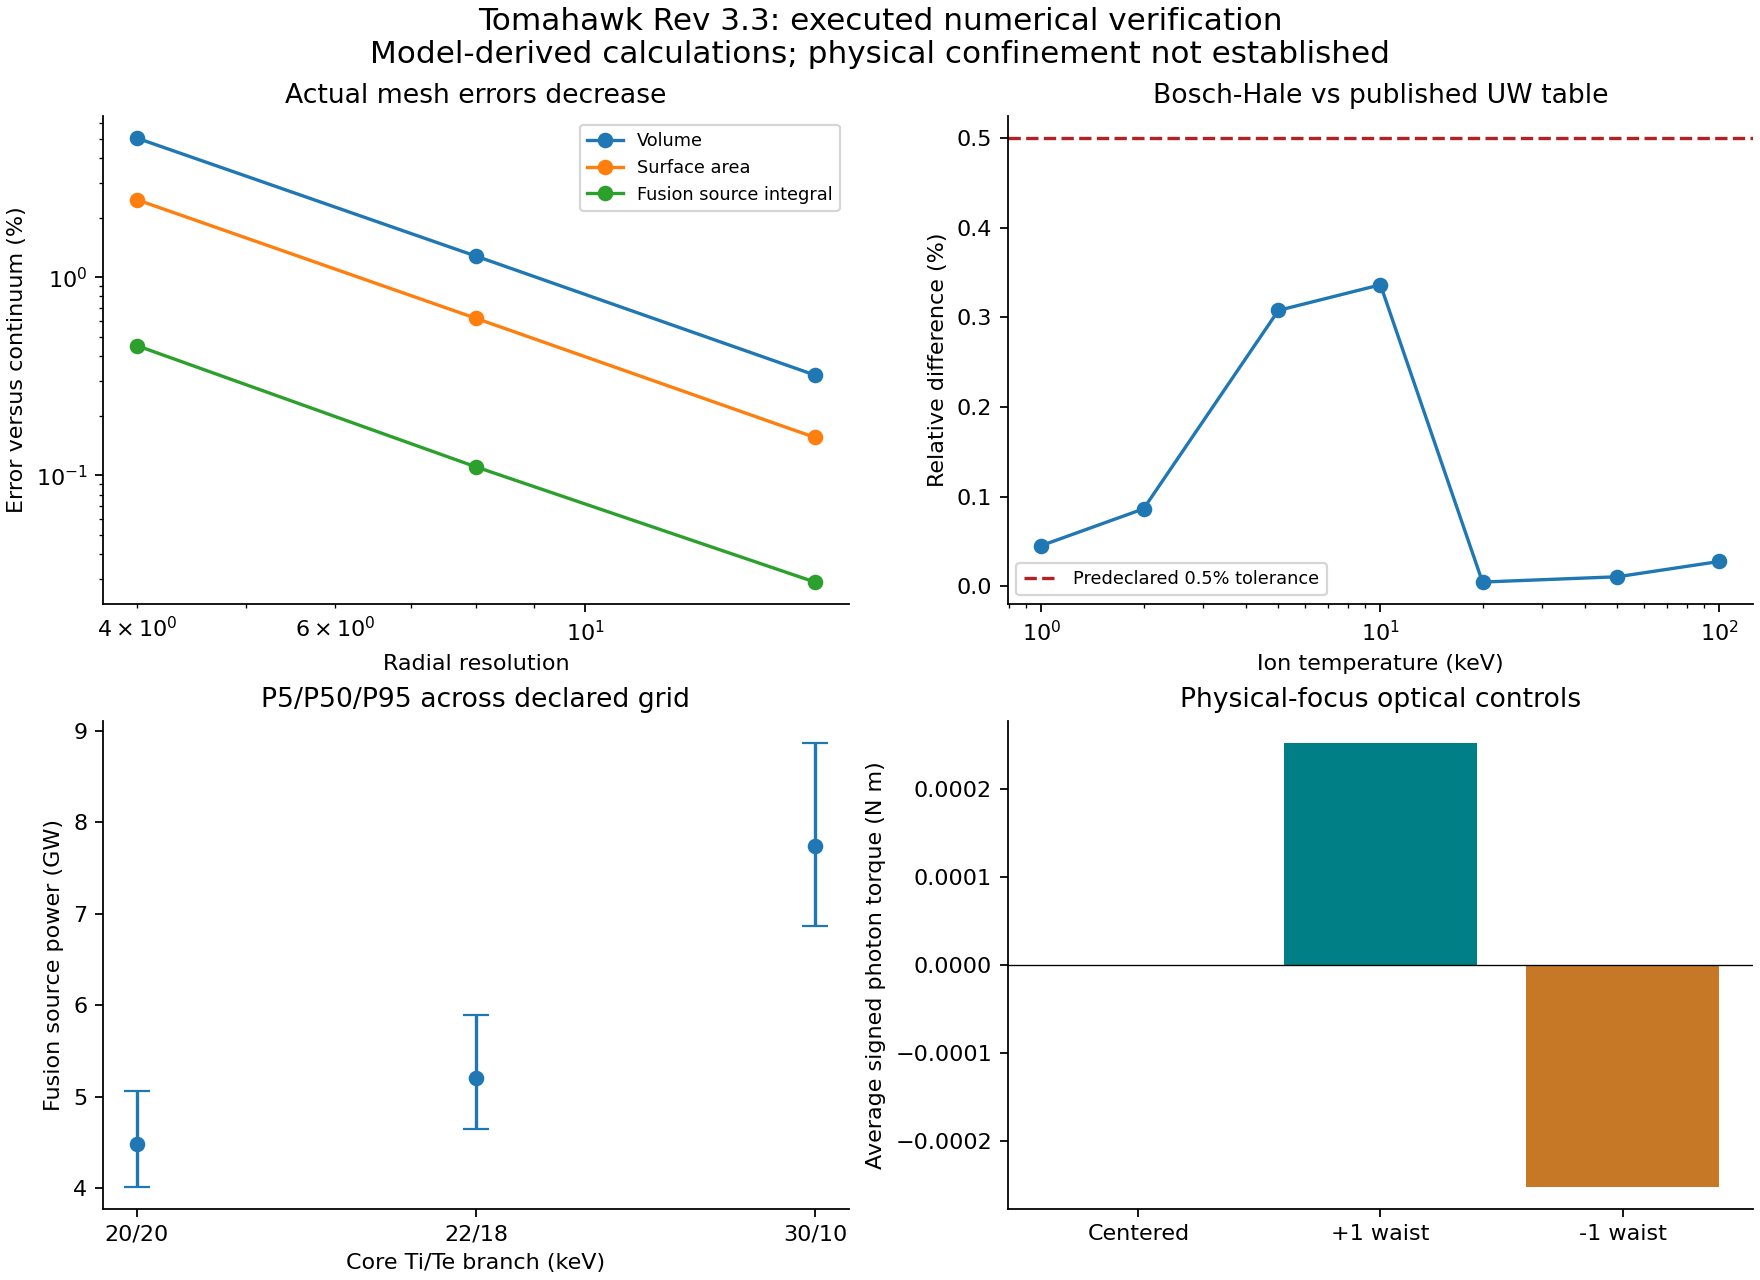
